# IA26_P01_G02 — Agente de routing para distribuição de produtos locais
**Inteligência Artificial 2026/27 · Licenciatura em Engenharia de Sistemas Informáticos (UPCA)**
**Trabalho Prático 1 · Notebook principal (small)**

| Nome | Nº de aluno |
|---|---|
| André Rodrigues | 26900 |
| Tiago Gonçalves | 29389 |
| Fábio Ferreira | 29365 |
| Alexandre Silva | 29382 |

## 1. Introdução

### 1.1 Contexto
**A procura de alimentos locais cresce na UE**, mas os pequenos produtores têm custos logísticos altos. Uma plataforma digital pode ligar três atores:
- **produtores**: pequenas explorações com fruta, legumes e outros produtos;
- **clientes**: fazem encomendas e escolhem o local de entrega;
- **centros de recolha (armazéns)**: juntam os produtos antes da distribuição e têm uma frota de veículos.

**O desafio é o routing:** escolher rotas de recolha e entrega eficientes, que respeitem as janelas temporais de disponibilidade nos produtores e de entrega nos clientes.

### 1.2 Objetivo
Desenvolver um **agente inteligente** que planeie as rotas dos veículos do armazém, recolhendo nos produtores e entregando nos clientes. O agente minimiza os quilómetros e respeita:
- as **janelas temporais** (o serviço começa dentro da janela);
- a **capacidade** de cada veículo;
- o **fluxo obrigatório** produtor → armazém → cliente;
- a **permanência máxima de 24 h** no armazém.

### 1.3 Organização
O notebook segue a estrutura do guia:

| Secção | Parte do guia | Entregável pedido | Onde está o código |
|---|---|---|---|
| 1 | Introdução | contexto, objetivo, grupo | este notebook |
| 2 | EDA | `01_eda_tiny.ipynb` | `01_eda_tiny.ipynb` (aqui fica o resumo) |
| 3 | Modelação | `model.py` + testes com rotas escritas à mão | `model.py`, `testes_modelo.py` |
| 4.1 | Pesquisa informada | Greedy e A* com 2 heurísticas, nós expandidos | este notebook |
| 4.2 | CSP | variáveis, domínios, restrições, restrições suaves, atribuição viável, nº de backtracks | este notebook |
| 4.3 | Pesquisa informada (cont.) | **rotas dos 2 veículos** | este notebook |
| 4.4 | Pesquisa local | Hill-Climbing sobre o Greedy, curvas custo × iteração | este notebook |
| 5 | Análise de resultados | melhores soluções, tempos, comparação, melhorias | este notebook |
| 6 | Conclusão | resultados, processo, ferramentas | este notebook |

Como pede o guia (*"code and documentation merged into a Jupyter Notebook"*), **o código da resolução está neste notebook**, cada parte junto do texto que a explica. Fora dele ficam só o `model.py` e os seus testes (`testes_modelo.py`), que são o entregável da modelação, e a EDA (`01_eda_tiny.ipynb`).

Em cada secção há uma tabela **"Opções consideradas"**, com as alternativas que pesámos, a escolhida e porquê.

In [1]:
# Bibliotecas usadas
import heapq
import itertools
import time
from dataclasses import dataclass
from datetime import date, datetime, timedelta
from datetime import time as hora
from typing import Callable, Dict, FrozenSet, Iterator, List, Optional, Set, Tuple

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from constraint import FunctionConstraint, Unassigned          # python-constraint (CSP)
from constraint import Problem as ProblemaCSP

# Modelação (entregável model.py): classes, leitura dos CSVs, custo e verificadores
from model import Problem, Request, State, verificar_solucao

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

PASTA = "docs/data_small_30_31oct2026/"          # <- única linha que muda entre o notebook principal (tiny) e o do small

# No tiny pedimos à python-constraint TODAS as atribuições (são poucas); no small só as primeiras.
MAX_SOLUCOES = 100_000 if "tiny" in PASTA else 30

problema = Problem(PASTA)
encomendas = {r.order_id for r in problema.pedidos.values()}
print(f"{len(problema.pedidos)} itens · {len(encomendas)} encomendas · {len(problema.veiculos)} veículos")

80 itens · 25 encomendas · 2 veículos


## 2. Análise exploratória (EDA)

A EDA completa está em **`01_eda_tiny.ipynb`**, e há uma igual para o small. Inclui a leitura e o *parsing* dos 12 CSVs, as contagens, a qualidade dos dados, as janelas, as distâncias e a capacidade. Aqui fica o resumo que orienta a modelação.

In [2]:
# Resumo dos dados carregados em memória (classe Problem do model.py)
W = problema.armazem
pesos = {}
for r in problema.pedidos.values():
    pesos[r.dia_recolha] = pesos.get(r.dia_recolha, 0) + r.weight_kg
noite = [r for r in problema.pedidos.values() if r.dia_recolha != r.dia_entrega]
display(pd.DataFrame([
    {"Indicador": "Paragens (produtores, armazém, clientes)", "Valor": len(problema.paragens)},
    {"Indicador": "Produtores", "Valor": sum(p["tipo"] == "producer" for p in problema.paragens.values())},
    {"Indicador": "Encomendas / itens", "Valor": f"{len(encomendas)} / {len(problema.pedidos)}"},
    {"Indicador": "Veículos (capacidade)", "Valor": ", ".join(f"{v}: {x.capacity_kg:.0f} kg" for v, x in problema.veiculos.items())},
    {"Indicador": "Peso recolhido por dia", "Valor": ", ".join(f"{d:%d/%m}: {p:.1f} kg" for d, p in sorted(pesos.items()))},
    {"Indicador": "Itens que passam a noite no armazém", "Valor": f"{len(noite)} (encomendas {sorted({r.order_id for r in noite})})"},
    {"Indicador": "Regras (rules.csv)", "Valor": f"serviço {problema.tempo_servico_min:.0f} min · armazém {problema.tempo_armazem_min:.0f} min · máx. {problema.permanencia_max_h:.0f} h no armazém"},
]))

,Indicador,Valor
0,"Paragens (produtores, armazém, clientes)",14
1,Produtores,6
2,Encomendas / itens,25 / 80
3,Veículos (capacidade),"1: 250 kg, 2: 300 kg"
4,Peso recolhido por dia,"30/10: 338.7 kg, 31/10: 241.3 kg"
5,Itens que passam a noite no armazém,"20 (encomendas [5, 11, 14, 17, 23, 25])"
6,Regras (rules.csv),serviço 10 min · armazém 15 min · máx. 24 h no...


**Conclusões da EDA usadas na modelação:**
- **Fluxo:** todos os produtos passam pelo armazém (regra `flow`). Cada encomenda junta produtos de vários produtores.
- **Dois dias, 30 e 31/10:** algumas encomendas são recolhidas a 30 e entregues a 31, por isso dormem no armazém (máximo 24 h).
- **Janelas:** limitam o **início** do serviço (`window_semantics = service_start`). Pode-se esperar.
- **Capacidade:** nenhuma encomenda excede um veículo, mas o peso de um dia inteiro pode exceder o veículo mais pequeno.
- **Distâncias:** a matriz é a linha reta × 1,3. Há pequenas violações da desigualdade triangular por arredondamento, corrigidas com Floyd-Warshall nas heurísticas.

## 3. Modelação

### 3.1 Opções consideradas e decisões

| Decisão | Opções consideradas | Escolha | Porquê |
|---|---|---|---|
| Custo a minimizar | km · tempo · km + tempo | **km** | É o que se quer reduzir. O tempo entra como restrição (janelas) |
| Fluxo | direto produtor → cliente · sempre pelo armazém | **sempre pelo armazém** | Regra `flow` do `rules.csv` |
| Encomenda | itens soltos · encomenda inteira | **entrega inteira** | Todos os itens de uma encomenda têm o mesmo cliente e a mesma janela |
| Dois dias | um problema único · dia a dia em sequência | **dia a dia** | Só se ligam pelos itens que dormem no armazém (passa-se a hora de chegada para as 24 h) |
| Janelas | limitam o início · limitam o fim do serviço | **o início** | `window_semantics = service_start` |
| Tempos de serviço | por item · por paragem | **por paragem** (10 min) e **por visita ao armazém** (15 min a descarregar, 15 min a carregar) | `stop_service_min` e `warehouse_handling_min` |
| Distâncias das heurísticas | matriz original · Floyd-Warshall | **Floyd-Warshall** | Garante a desigualdade triangular, de que a admissibilidade precisa |
| Estado repetido | com ou sem a hora | **com a hora** | Com janelas, chegar mais tarde ao mesmo sítio não é equivalente |
| Hora de saída | livre · fixa | **06:00** (suposição) | Testámos 04:00 e não muda nada, porque as janelas abrem mais tarde |

### 3.2 Classes (`model.py`)

| Classe | Representa | Principais campos e métodos |
|---|---|---|
| `Request` | um item de uma encomenda (pedido de transporte) | produtor, cliente, peso, janelas de disponibilidade e de entrega |
| `Vehicle` | um veículo da frota | capacidade, refrigerado, velocidade |
| `Problem` | a instância inteira, lida dos 12 CSVs | paragens, veículos, pedidos, matrizes de km e de tempo, regras, `custo_rota`, `verificar_viabilidade` |
| `State` | um estado da pesquisa | paragem atual, hora, carga, fase de cada item (no produtor → a bordo → no armazém → carregado → entregue), `chave()` |

E ainda `verificar_solucao`, que verifica uma solução completa: vários veículos e vários dias, com cada item entregue uma só vez.

As heurísticas e os algoritmos estão na secção 4, junto da técnica que os usa.

In [3]:
# Um item (Request) e os veículos (Vehicle) tal como ficam em memória
exemplo = next(iter(problema.pedidos.values()))
display(pd.DataFrame([vars(exemplo)]))
display(pd.DataFrame([vars(v) for v in problema.veiculos.values()]))

,item_id,order_id,product_name,weight_kg,pickup_loc,delivery_loc,availability_start,availability_end,delivery_start,delivery_end
0,1,1,Curgete,12.0,3,12,2026-10-30 07:45:00,2026-10-30 10:45:00,2026-10-30 12:30:00,2026-10-30 14:30:00


,vehicle_id,plate,capacity_kg,refrigerated,avg_speed_kmh,center_loc
0,1,ZG-06-DP,250.0,True,45.0,7
1,2,TY-74-YA,300.0,False,45.0,7


### 3.3 Função de custo e verificador com rotas escritas à mão

Uma rota é uma lista de ações: `("pickup", item)`, `("warehouse", W)`, `("load", item)` e `("delivery", item)`. O verificador simula a rota passo a passo e confirma:
- as janelas;
- a capacidade;
- o fluxo produtor → armazém → cliente;
- os tempos de serviço;
- as 24 h no armazém.

Abaixo há duas rotas escritas à mão para a primeira encomenda que é entregue no mesmo dia: uma correta e outra que salta o armazém.

In [4]:
from datetime import datetime, time as hora_do_dia

def rota_simples(encomenda):
    """Rota escrita à mão: produtores (pela janela que fecha primeiro) → armazém → cliente → armazém."""
    itens = sorted([r for r in problema.pedidos.values() if r.order_id == encomenda],
                   key=lambda r: r.availability_end)
    produtores = list(dict.fromkeys(r.pickup_loc for r in itens))
    return ([("pickup", r.item_id) for p in produtores for r in itens if r.pickup_loc == p]
            + [("warehouse", W)] + [("load", r.item_id) for r in itens]
            + [("delivery", r.item_id) for r in itens] + [("warehouse", W)]), itens

# primeira encomenda do mesmo dia cuja rota simples é viável
for enc in sorted(encomendas):
    rota, itens = rota_simples(enc)
    partida = datetime.combine(itens[0].dia_recolha, hora_do_dia(6, 0))
    if itens[0].dia_recolha == itens[0].dia_entrega and \
       problema.verificar_viabilidade(1, rota, partida, exigir_rota_completa=True)["viavel"]:
        break

ok = problema.verificar_viabilidade(1, rota, partida, exigir_rota_completa=True)
print(f"Rota correta (encomenda {enc}): viável={ok['viavel']} · {ok['distancia_km']} km · "
      f"termina às {ok['hora_fim']:%H:%M}")
print("Paragens e custo:", problema.custo_rota([W] + [problema.pedidos[a].pickup_loc if t == "pickup" else
      problema.pedidos[a].delivery_loc if t == "delivery" else W for t, a in rota if t != "load"]))

sem_armazem = [a for a in rota if a[0] == "pickup"] + [a for a in rota if a[0] == "delivery"]
erro = problema.verificar_viabilidade(1, sem_armazem, partida)
print(f"\nRota sem passar pelo armazém: viável={erro['viavel']}")
print("Primeiro erro:", erro["erros"][0])

Rota correta (encomenda 1): viável=True · 200.59 km · termina às 13:49
Paragens e custo: {'distancia_km': 200.59, 'tempo_viagem_min': 267.5}

Rota sem passar pelo armazém: viável=False
Primeiro erro: Item 2: tentativa de entrega sem ter sido previamente recolhido e carregado no armazém.


### 3.4 Testes do `model.py` com rotas escritas à mão (`testes_modelo.py`)

São 11 testes com `assert`. Cada teste escreve uma rota à mão e confirma que o verificador a aceita ou a rejeita pelo motivo certo:
- **rota válida e função de custo;**
- **uma rota inválida para cada regra:** fluxo sem armazém, janela de recolha, capacidade, janela de entrega e 24 h;
- **soluções completas:** com 2 veículos, e com uma encomenda esquecida;
- **modelo:** a `chave()` do estado e a desigualdade triangular.

As verificações das heurísticas, da pesquisa, do CSP e do Hill-Climbing estão na secção 4, a seguir ao código de cada técnica.

In [5]:
from testes_modelo import executar_todos
todos_passaram = executar_todos()

  ✓ teste_rota_valida
  ✓ teste_custo_da_rota
  ✓ teste_fluxo_sem_armazem
  ✓ teste_janela_de_recolha
  ✓ teste_capacidade
  ✓ teste_janela_de_entrega
  ✓ teste_permanencia_24h
  ✓ teste_solucao_dois_veiculos
  ✓ teste_solucao_com_item_esquecido
  ✓ teste_chave_ignora_historico
  ✓ teste_floyd_warshall_desigualdade_triangular

11 de 11 testes passaram.


## 4. Resolução do problema

### 4.0 Como as técnicas trabalham juntas

```
encomendas ─► tarefas ─► CSP: que veículo faz cada tarefa? ─► A*: rota de cada veículo em cada dia ─► verificador
                                                                     │
                                            Greedy (rápido) ─► Hill-Climbing (melhora) ─► verificador
```

O guia apresenta a pesquisa informada, a pesquisa local e o CSP por esta ordem, e diz que a estrutura *"can be adapted"*. Adaptámos a ordem porque as técnicas dependem umas das outras:

| Secção | Conteúdo | Porquê nesta ordem |
|---|---|---|
| 4.1 | **Pesquisa informada**: heurísticas, sucessores, UCS, Greedy e A*, com um teste num só veículo | O CSP precisa dela, para saber se um conjunto de tarefas tem rota |
| 4.2 | **CSP**: divide as tarefas pelos 2 veículos | As rotas dos 2 veículos precisam da divisão |
| 4.3 | **Rotas dos 2 veículos**: a pesquisa informada aplicada à divisão do CSP, nos 2 dias | Entregável *"routes for the 2 tiny vehicles"* |
| 4.4 | **Pesquisa local**: Hill-Climbing sobre a solução do Greedy da 4.3 | Precisa das rotas do Greedy |

### 4.1 Pesquisa informada

#### 4.1.1 Heurísticas

As duas estimam os **km que faltam** a partir de um estado. Para o A\* dar o ótimo, têm de ser **admissíveis**, ou seja, nunca exagerar. Nas fórmulas, *d* é a distância corrigida por Floyd-Warshall e W o armazém.

| Heurística | Ideia | Porque é admissível | Visão |
|---|---|---|---|
| **h1 · pedido mais caro** | Para cada item que falta, o percurso obrigatório que lhe resta (produtor → armazém → cliente → armazém, conforme a fase do item). Fica o **maior** | Esse item tem mesmo de fazer esse percurso, e com Floyd-Warshall não há atalhos | **individual**: o pior item |
| **h2 · árvore geradora mínima** | Custo da árvore mínima (Prim) que liga a posição atual, o armazém e todas as paragens que faltam | Qualquer rota que passe por todas essas paragens também as liga | **global**: o conjunto das paragens |

**Opções consideradas e postas de lado:**

| Opção | Porque não |
|---|---|
| Linha reta | Aqui a matriz é a linha reta × 1,3: seria a mesma informação, só que mais fraca |
| Paragem mais distante + regresso (ideia inicial do Fábio) | Foi o ponto de partida. A h1 estende-a ao percurso obrigatório de cada item, por isso é sempre maior ou igual e substitui-a |
| max(h1, h2) | Ganha muito pouco à h1 e não acrescenta uma ideia nova |
| Urgência (janelas a fechar) | Mede tempo, não km; não é admissível para o custo em km |

**Porquê estas duas:** olham para o problema de formas diferentes, uma para *o pior item* e outra para *o conjunto das paragens*, e as duas são admissíveis.

As duas aceitam `so_recolher`: itens que hoje só têm de chegar ao armazém, porque são entregues no dia seguinte.

In [6]:
# Heurísticas para o Greedy e o A*
#
# As duas estimam os km que faltam e nunca exageram (são admissíveis): são obtidas
# por relaxação do problema (ignoram janelas e capacidade) e usam as distâncias
# corrigidas por Floyd-Warshall, que respeitam a desigualdade triangular.
# Partimos da ideia inicial do Fábio (paragem pendente mais distante + regresso) e
# estendemo-la ao percurso obrigatório de cada item (h1) e ao conjunto das paragens (h2).

def percurso_obrigatorio(state: State, problem: Problem, req: Request, so_recolha: bool = False) -> float:
    """
    km mínimos que ainda faltam a UM item, a partir da posição atual, seguindo o
    fluxo obrigatório produtor -> armazém -> cliente e terminando no armazém.
    Depende da fase em que o item está.
    Com so_recolha=True o item só tem de chegar hoje ao armazém (é entregue amanhã).
    """
    d = problem.distancia_inferior_entre
    atual, W = state.paragem_atual, problem.armazem
    iid = req.item_id

    if so_recolha:
        if iid in state.no_armazem:                              # já está no armazém
            return d(atual, W)
        if iid in state.recolhidos_a_bordo:                      # falta levá-lo ao armazém
            return d(atual, W)
        return d(atual, req.pickup_loc) + d(req.pickup_loc, W)   # recolher e levar ao armazém

    if iid in state.entregues:                                   # já entregue
        return 0.0
    if iid in state.para_entrega_a_bordo:                        # já carregado: entregar e voltar
        return d(atual, req.delivery_loc) + d(req.delivery_loc, W)
    if iid in state.recolhidos_a_bordo or iid in state.no_armazem:   # falta armazém, entregar e voltar
        return d(atual, W) + d(W, req.delivery_loc) + d(req.delivery_loc, W)
    # ainda no produtor: recolher, armazém, entregar e voltar
    return (d(atual, req.pickup_loc) + d(req.pickup_loc, W)
            + d(W, req.delivery_loc) + d(req.delivery_loc, W))


def h_pedido_mais_caro(state: State, problem: Problem, itens_objetivo: Set[int],
                       so_recolher: Set[int] = frozenset()) -> float:
    """
    h1 · Pedido mais caro (visão individual).

    O maior percurso obrigatório entre os itens que faltam. Admissível: esse item
    tem mesmo de fazer esse percurso, e não há atalhos (desigualdade triangular).
    Estende a ideia inicial do Fábio (paragem mais distante + regresso): soma as várias
    paragens obrigatórias de um item em vez de olhar para cada paragem em separado.
    """
    custos = [percurso_obrigatorio(state, problem, problem.pedidos[iid])
              for iid in itens_objetivo if iid not in state.entregues]
    custos += [percurso_obrigatorio(state, problem, problem.pedidos[iid], so_recolha=True)
               for iid in so_recolher if iid not in state.no_armazem]
    if not custos:
        return problem.distancia_inferior_entre(state.paragem_atual, problem.armazem)
    return max(custos)


def h_arvore_minima(state: State, problem: Problem, itens_objetivo: Set[int],
                    so_recolher: Set[int] = frozenset()) -> float:
    """
    h2 · Árvore geradora mínima (visão global).

    Custo da árvore de menor peso que liga a posição atual, o armazém e todas as
    paragens que faltam visitar (algoritmo de Prim). Admissível: qualquer rota que
    passe por todas essas paragens também as liga a todas. As ligações de custo 0
    (paragens no mesmo local) são incluídas, para a árvore nunca sobrestimar.
    """
    d = problem.distancia_inferior_entre
    pendentes = state.paragens_pendentes(problem, itens_objetivo, so_recolher)
    if not pendentes:
        return d(state.paragem_atual, problem.armazem)

    nos = set(pendentes) | {state.paragem_atual, problem.armazem}
    ligados = {state.paragem_atual}
    custo = 0.0
    # Prim: em cada passo junta o nó mais barato de ligar à árvore
    melhor = {no: d(state.paragem_atual, no) for no in nos if no not in ligados}
    while melhor:
        no = min(melhor, key=melhor.get)
        custo += melhor.pop(no)
        ligados.add(no)
        for outro in melhor:
            melhor[outro] = min(melhor[outro], d(no, outro))
    return custo


HEURISTICAS = {
    "h1 pedido mais caro": h_pedido_mais_caro,
    "h2 árvore mínima": h_arvore_minima,
}

#### 4.1.2 Estados, ações e objetivo

- **Estado:** a classe `State` do `model.py` (paragem, hora, carga e fase de cada item).
- **Ações** (função `sucessores`):
  1. **recolher num produtor** os itens disponíveis, numa visita de 10 min. Se chegar antes de a janela abrir, espera;
  2. **ir ao armazém:** descarregar o que foi recolhido (15 min) e carregar as encomendas completas que cabem (15 min);
  3. **entregar num cliente** as encomendas a bordo, dentro da janela.
- **Poda** (`sem_saida`): corta os estados em que alguma janela já fechou ou algum item já passou das 24 h no armazém.
- **Objetivo** (`e_objetivo`): os itens entregues, os itens só de recolha no armazém e o veículo de volta ao armazém.
- **Custo** de cada passo: os km da matriz (`problem.distancia_entre`).

In [7]:
# Gerador de sucessores, poda e teste de objetivo

Acao = Tuple[str, int]


def _encomendas_completas_no_armazem(state: State, problem: Problem, itens_objetivo: Set[int]) -> Dict[int, List[int]]:
    """Encomendas cujos itens-objetivo estão TODOS no armazém (prontas a carregar)."""
    por_encomenda: Dict[int, List[int]] = {}
    for iid in itens_objetivo:
        por_encomenda.setdefault(problem.pedidos[iid].order_id, []).append(iid)
    return {
        enc: sorted(itens) for enc, itens in por_encomenda.items()
        if all(i in state.no_armazem for i in itens)
    }


def sucessores(state: State, problem: Problem, vehicle_id: int, itens_objetivo: Set[int],
               so_recolher: Set[int] = frozenset()):
    """Devolve a lista de (acoes, novo_estado, custo_km) possíveis a partir de um estado."""
    veiculo = problem.veiculos[vehicle_id]
    W = problem.armazem
    servico = timedelta(minutes=problem.tempo_servico_min)
    manuseamento = timedelta(minutes=problem.tempo_armazem_min)
    lista = []

    no_produtor = [
        problem.pedidos[i] for i in (itens_objetivo | so_recolher)
        if i not in state.recolhidos_a_bordo and i not in state.no_armazem
        and i not in state.para_entrega_a_bordo and i not in state.entregues
    ]

    # ---------------------------------------------------------------
    # 1. Recolher num produtor
    # ---------------------------------------------------------------
    for produtor in sorted({r.pickup_loc for r in no_produtor}):
        if produtor == state.paragem_atual:
            continue          # uma nova visita ao mesmo produtor obriga a sair primeiro
        chegada = state.tempo_atual + timedelta(minutes=problem.tempo_entre(state.paragem_atual, produtor))
        candidatos = [r for r in no_produtor if r.pickup_loc == produtor]
        # horas de início possíveis: chegar logo, ou esperar que abra a janela de cada item
        inicios = sorted({max(chegada, r.availability_start) for r in candidatos})
        vistos = set()
        for inicio in inicios:
            carga = state.carga_atual_kg
            escolhidos = []
            for r in sorted(candidatos, key=lambda r: r.availability_end):
                if r.availability_start <= inicio <= r.availability_end and carga + r.weight_kg <= veiculo.capacity_kg + 1e-6:
                    escolhidos.append(r)
                    carga += r.weight_kg
            ids = frozenset(r.item_id for r in escolhidos)
            if not ids or ids in vistos:
                continue
            vistos.add(ids)
            # o serviço começa quando o veículo chega e todos os itens escolhidos já estão disponíveis
            inicio = max([chegada] + [r.availability_start for r in escolhidos])
            km = problem.distancia_entre(state.paragem_atual, produtor)
            novo = State(
                paragem_atual=produtor,
                tempo_atual=inicio + servico,
                carga_atual_kg=carga,
                recolhidos_a_bordo=state.recolhidos_a_bordo | ids,
                no_armazem=state.no_armazem,
                para_entrega_a_bordo=state.para_entrega_a_bordo,
                entregues=state.entregues,
                distancia_acumulada_km=state.distancia_acumulada_km + km,
                historico_paragens=state.historico_paragens + (produtor,),
                chegadas_armazem=state.chegadas_armazem,
            )
            lista.append(([("pickup", i) for i in sorted(ids)], novo, km))

    # ---------------------------------------------------------------
    # 2. Ir ao armazém: descarregar e carregar encomendas completas
    # ---------------------------------------------------------------
    chegada = state.tempo_atual + timedelta(minutes=problem.tempo_entre(state.paragem_atual, W))
    relogio = chegada
    carga = state.carga_atual_kg
    no_armazem = set(state.no_armazem)
    chegadas = dict(state.chegadas_armazem)
    acoes: List[Acao] = [("warehouse", W)]
    if state.recolhidos_a_bordo:                                  # descarregar
        relogio += manuseamento
        for i in state.recolhidos_a_bordo:
            no_armazem.add(i)
            chegadas[i] = chegada
            carga -= problem.pedidos[i].weight_kg
    estado_tmp = State(W, relogio, carga, frozenset(), frozenset(no_armazem),
                       state.para_entrega_a_bordo, state.entregues)
    carregar = []
    for enc, itens in sorted(_encomendas_completas_no_armazem(estado_tmp, problem, itens_objetivo).items(),
                             key=lambda e: min(problem.pedidos[i].delivery_end for i in e[1])):
        peso = sum(problem.pedidos[i].weight_kg for i in itens)
        dentro_24h = all((relogio - chegadas[i]).total_seconds() / 3600 <= problem.permanencia_max_h + 1e-6 for i in itens)
        if carga + peso <= veiculo.capacity_kg + 1e-6 and dentro_24h:
            carregar.extend(itens)
            carga += peso
    if carregar:                                                  # carregar
        relogio += manuseamento
        for i in carregar:
            no_armazem.discard(i)
            chegadas.pop(i, None)
        acoes += [("load", i) for i in carregar]

    tudo_feito = itens_objetivo <= state.entregues and so_recolher <= state.no_armazem
    if state.recolhidos_a_bordo or carregar or (tudo_feito and state.paragem_atual != W):
        km = problem.distancia_entre(state.paragem_atual, W)
        novo = State(
            paragem_atual=W,
            tempo_atual=relogio,
            carga_atual_kg=carga,
            recolhidos_a_bordo=frozenset(),
            no_armazem=frozenset(no_armazem),
            para_entrega_a_bordo=state.para_entrega_a_bordo | frozenset(carregar),
            entregues=state.entregues,
            distancia_acumulada_km=state.distancia_acumulada_km + km,
            historico_paragens=state.historico_paragens + (W,),
            chegadas_armazem=tuple(sorted(chegadas.items())),
        )
        lista.append((acoes, novo, km))

    # ---------------------------------------------------------------
    # 3. Entregar num cliente as encomendas a bordo
    # ---------------------------------------------------------------
    a_bordo = [problem.pedidos[i] for i in state.para_entrega_a_bordo]
    for cliente in sorted({r.delivery_loc for r in a_bordo}):
        if cliente == state.paragem_atual:
            continue
        chegada = state.tempo_atual + timedelta(minutes=problem.tempo_entre(state.paragem_atual, cliente))
        itens = [r for r in a_bordo if r.delivery_loc == cliente]
        inicio = max([chegada] + [r.delivery_start for r in itens])
        if any(inicio > r.delivery_end for r in itens):
            continue                       # não é possível entregar tudo a tempo nesta visita
        ids = frozenset(r.item_id for r in itens)
        km = problem.distancia_entre(state.paragem_atual, cliente)
        novo = State(
            paragem_atual=cliente,
            tempo_atual=inicio + servico,
            carga_atual_kg=state.carga_atual_kg - sum(r.weight_kg for r in itens),
            recolhidos_a_bordo=state.recolhidos_a_bordo,
            no_armazem=state.no_armazem,
            para_entrega_a_bordo=state.para_entrega_a_bordo - ids,
            entregues=state.entregues | ids,
            distancia_acumulada_km=state.distancia_acumulada_km + km,
            historico_paragens=state.historico_paragens + (cliente,),
            chegadas_armazem=state.chegadas_armazem,
        )
        lista.append(([("delivery", i) for i in sorted(ids)], novo, km))

    return lista


def sem_saida(state: State, problem: Problem, itens_objetivo: Set[int],
              so_recolher: Set[int] = frozenset()) -> bool:
    """Corta estados que já não podem cumprir alguma janela ou as 24 h (poda simples)."""
    chegadas = dict(state.chegadas_armazem)
    for i in itens_objetivo | so_recolher:
        r = problem.pedidos[i]
        if i in state.entregues:
            continue
        no_produtor = not (i in state.recolhidos_a_bordo or i in state.no_armazem or i in state.para_entrega_a_bordo)
        if no_produtor and state.tempo_atual > r.availability_end:
            return True                    # a janela de recolha já fechou
        if i in so_recolher:
            continue                       # só é entregue amanhã
        if state.tempo_atual > r.delivery_end:
            return True                    # a janela de entrega já fechou
        if i in state.no_armazem and i in chegadas:
            horas = (state.tempo_atual - chegadas[i]).total_seconds() / 3600
            if horas > problem.permanencia_max_h + 1e-6:
                return True                # já passou das 24 h no armazém
    return False


def e_objetivo(state: State, problem: Problem, itens_objetivo: Set[int],
               so_recolher: Set[int] = frozenset()) -> bool:
    """Objetivo: itens entregues, itens so_recolher no armazém e veículo de volta ao armazém."""
    return (itens_objetivo <= state.entregues and so_recolher <= state.no_armazem
            and state.paragem_atual == problem.armazem)

#### 4.1.3 UCS, Greedy e A*

Os três algoritmos usam **a mesma função e o mesmo gerador de sucessores**. Só muda a ordem da fila de prioridade:

| Algoritmo | Escolhe primeiro o estado com menor… | Garante a melhor rota? |
|---|---|---|
| UCS | *g*, os km já feitos | sim |
| Greedy | *h*, a estimativa do que falta | não |
| A* | *g + h* | sim, se *h* for admissível |

A função conta os **nós expandidos** e deteta estados repetidos com `State.chave()`.

**Opções consideradas:**

| Algoritmo | Garante a melhor rota? | Papel no trabalho |
|---|---|---|
| UCS (custo uniforme) | sim | **referência** do ótimo: valida o A\* |
| Greedy best-first | não | **pedido pelo guia**: rápido e ponto de partida do Hill-Climbing |
| A\* | sim, com heurística admissível | **pedido pelo guia**: o algoritmo principal |
| Weighted A\*, IDA\*, beam search | não, ou repetem trabalho | **não usados**: perdem a garantia de ótimo (Weighted A\*, beam) ou repetem muitos estados com as janelas (IDA\*). Ficam como alternativas para instâncias grandes |

In [8]:
# Pesquisa: UCS, Greedy e A* (a mesma função; muda a prioridade)

def procurar(
    problem: Problem,
    vehicle_id: int,
    itens_objetivo: Set[int],
    hora_partida: datetime,
    algoritmo: str = "astar",
    heuristica: Optional[Callable] = None,
    limite_nos: int = 2_000_000,
    so_recolher: Optional[Set[int]] = None,
    armazem_inicial: Optional[Dict[int, datetime]] = None,
) -> Dict[str, object]:
    """
    Procura uma rota para um veículo.
      algoritmo: "ucs", "greedy" ou "astar"
      heuristica: função h(state, problem, itens_objetivo, so_recolher) (ignorada na UCS)
      so_recolher: itens a recolher hoje e deixar no armazém (entregues amanhã)
      armazem_inicial: {item: hora de chegada} dos itens que já estão no armazém
    Devolve a rota (lista de ações), os km, os nós expandidos e o tempo de execução.
    """
    itens_objetivo = frozenset(itens_objetivo)
    so_recolher = frozenset(so_recolher or ())
    armazem_inicial = dict(armazem_inicial or {})
    if algoritmo == "ucs" or heuristica is None:
        h = lambda s, p, o, r: 0.0
    else:
        h = heuristica
    inicio_relogio = time.perf_counter()

    inicial = State(paragem_atual=problem.armazem, tempo_atual=hora_partida,
                    no_armazem=frozenset(armazem_inicial),
                    historico_paragens=(problem.armazem,),
                    chegadas_armazem=tuple(sorted(armazem_inicial.items())))
    contador = itertools.count()                  # desempate na fila de prioridade
    def prioridade(s: State) -> float:
        if algoritmo == "greedy":
            return h(s, problem, itens_objetivo, so_recolher)
        if algoritmo == "ucs":
            return s.distancia_acumulada_km
        return s.distancia_acumulada_km + h(s, problem, itens_objetivo, so_recolher)

    fila = [(prioridade(inicial), next(contador), inicial, [], (inicial,))]
    melhor_g = {inicial.chave(): 0.0}
    expandidos = 0

    while fila:
        _, _, estado, acoes, caminho = heapq.heappop(fila)
        g = estado.distancia_acumulada_km
        if algoritmo != "greedy" and g > melhor_g.get(estado.chave(), float("inf")) + 1e-9:
            continue                               # entrada desatualizada na fila
        if e_objetivo(estado, problem, itens_objetivo, so_recolher):
            return {
                "encontrou": True, "acoes": acoes, "km": round(g, 2),
                "nos_expandidos": expandidos,
                "tempo_s": round(time.perf_counter() - inicio_relogio, 3),
                "paragens": estado.historico_paragens,
                "estados": caminho,                 # estados ao longo da rota (para análise)
            }
        expandidos += 1
        if expandidos > limite_nos:
            break
        for novas_acoes, novo, _ in sucessores(estado, problem, vehicle_id, itens_objetivo, so_recolher):
            if sem_saida(novo, problem, itens_objetivo, so_recolher):
                continue
            chave = novo.chave()
            if algoritmo == "greedy":
                if chave in melhor_g:
                    continue                       # o Greedy não revisita estados
                melhor_g[chave] = novo.distancia_acumulada_km
            else:
                if novo.distancia_acumulada_km >= melhor_g.get(chave, float("inf")) - 1e-9:
                    continue
                melhor_g[chave] = novo.distancia_acumulada_km
            heapq.heappush(fila, (prioridade(novo), next(contador), novo, acoes + novas_acoes, caminho + (novo,)))

    return {"encontrou": False, "acoes": None, "km": None, "nos_expandidos": expandidos,
            "tempo_s": round(time.perf_counter() - inicio_relogio, 3), "paragens": None, "estados": None}

#### 4.1.4 Teste num só veículo e verificação das heurísticas

**A instância de teste:** o maior veículo e as encomendas do primeiro dia que são recolhidas e entregues nesse dia. Juntam-se uma a uma, enquanto houver rota.

**O que se compara:** UCS, Greedy e A* com a h1 e com a h2.

**O que se confirma com `assert`:**
- o A* dá o mesmo custo que a UCS;
- nenhuma das heurísticas exagera em nenhum estado da rota ótima, ou seja, são admissíveis.

In [9]:
dia0 = min(r.dia_recolha for r in problema.pedidos.values())
partida0 = datetime.combine(dia0, hora(6, 0))
maior = max(problema.veiculos, key=lambda x: problema.veiculos[x].capacity_kg)
itens_teste, escolhidas = set(), []
for enc in sorted({r.order_id for r in problema.pedidos.values() if r.dia_recolha == dia0 == r.dia_entrega}):
    novos = itens_teste | {i for i, r in problema.pedidos.items() if r.order_id == enc}
    if procurar(problema, maior, novos, partida0, "astar", h_pedido_mais_caro)["encontrou"]:
        itens_teste, escolhidas = novos, escolhidas + [enc]
print(f"Instância de teste: veículo {maior}, dia {dia0:%d/%m}, encomendas {escolhidas} ({len(itens_teste)} itens)")

testes = [("UCS", "ucs", None)] + [(f"Greedy · {n.split()[0]}", "greedy", h) for n, h in HEURISTICAS.items()] \
         + [(f"A* · {n.split()[0]}", "astar", h) for n, h in HEURISTICAS.items()]
resultados_teste = {n: procurar(problema, maior, itens_teste, partida0, alg, h) for n, alg, h in testes}
ucs = resultados_teste["UCS"]
display(pd.DataFrame([{"Algoritmo": n, "km": r["km"], "Nós expandidos": r["nos_expandidos"], "Tempo (s)": r["tempo_s"],
                       "Paragens": " → ".join(map(str, r["paragens"]))} for n, r in resultados_teste.items()]))

# Estimativa de cada heurística no estado inicial, comparada com o custo real
inicial = ucs["estados"][0]
display(pd.DataFrame([{"Heurística": n, "Estimativa no início (km)": round(h(inicial, problema, itens_teste), 1),
                       "Custo real (km)": ucs["km"]} for n, h in HEURISTICAS.items()]))

# Verificações
for n, h in HEURISTICAS.items():
    assert abs(resultados_teste[f"A* · {n.split()[0]}"]["km"] - ucs["km"]) < 1e-6, n     # A* = UCS
for estado in ucs["estados"]:                                                          # ao longo da rota ótima
    falta = ucs["km"] - estado.distancia_acumulada_km
    for n, h in HEURISTICAS.items():
        assert h(estado, problema, itens_teste) <= falta + 1e-6, n                      # admissível
print("✓ O A* dá o mesmo custo que a UCS com a h1 e com a h2.")
print("✓ Nenhuma das heurísticas exagera ao longo da rota ótima (são admissíveis).")

Instância de teste: veículo 2, dia 30/10, encomendas [1, 2, 6, 15, 18] (17 itens)


,Algoritmo,km,Nós expandidos,Tempo (s),Paragens
0,UCS,262.55,1548,0.124,7 → 4 → 6 → 1 → 2 → 3 → 7 → 8 → 10 → 12 → 11 → 7
1,Greedy · h1,317.04,59,0.007,7 → 3 → 4 → 6 → 2 → 1 → 7 → 8 → 10 → 12 → 11 → 7
2,Greedy · h2,303.22,20,0.002,7 → 3 → 4 → 6 → 1 → 2 → 7 → 8 → 10 → 12 → 11 → 7
3,A* · h1,262.55,1000,0.123,7 → 4 → 6 → 1 → 2 → 3 → 7 → 8 → 10 → 12 → 11 → 7
4,A* · h2,262.55,1326,0.107,7 → 4 → 6 → 1 → 2 → 3 → 7 → 8 → 10 → 12 → 11 → 7


,Heurística,Estimativa no início (km),Custo real (km)
0,h1 pedido mais caro,162.8,262.55
1,h2 árvore mínima,135.1,262.55


✓ O A* dá o mesmo custo que a UCS com a h1 e com a h2.
✓ Nenhuma das heurísticas exagera ao longo da rota ótima (são admissíveis).


### 4.2 CSP — que veículo faz cada tarefa

#### 4.2.1 Do problema às tarefas

Cada encomenda é transformada em **tarefas**, uma por coisa que um veículo tem de fazer num dia:

| Tarefa | Significado | Exemplo |
|---|---|---|
| `C<n>` | **completa**: recolher e entregar no mesmo dia | `C4` |
| `R<n>-P<p>` | **recolha**: levar ao armazém os itens da encomenda *n* que estão no produtor *p* (a encomenda só é entregue no dia seguinte) | `R2-P1` |
| `E<n>` | **entrega**: carregar no armazém e entregar a encomenda *n* | `E2` |

**Porquê dividir assim?**
- A **entrega é sempre inteira**: todos os itens de uma encomenda têm a mesma janela de entrega e o mesmo cliente.
- A **recolha de uma encomenda do dia seguinte divide-se por produtor**: os itens juntam-se no armazém durante a noite, por isso cada produtor pode ser visitado por um veículo diferente. É para isto que serve o armazém (consolidar).
- Numa tarefa `C` a recolha não se divide: o mesmo veículo recolhe e entrega, o que evita que um veículo tenha de esperar por outro no mesmo dia.

In [10]:
# Tarefas: C (completa), R-P (recolha por produtor), E (entrega)

HORA_PARTIDA = hora(6, 0)          # suposição: os veículos saem do armazém às 06:00


@dataclass(frozen=True)
class Tarefa:
    nome: str                 # "C4", "R2", "E2"
    encomenda: int
    tipo: str                 # "completa", "recolha" ou "entrega"
    dia: date
    itens: FrozenSet[int]
    peso_kg: float
    paragens: FrozenSet[int]  # paragens que a tarefa obriga a visitar (além do armazém)

    @property
    def recolhe(self) -> bool:
        return self.tipo in ("completa", "recolha")

    @property
    def entrega(self) -> bool:
        return self.tipo in ("completa", "entrega")


def criar_tarefas(problem: Problem) -> List[Tarefa]:
    """Divide cada encomenda nas tarefas de cada dia."""
    por_encomenda: Dict[int, list] = {}
    for r in problem.pedidos.values():
        por_encomenda.setdefault(r.order_id, []).append(r)

    tarefas = []
    for enc, itens in sorted(por_encomenda.items()):
        ids = frozenset(r.item_id for r in itens)
        peso = round(sum(r.weight_kg for r in itens), 2)
        produtores = frozenset(r.pickup_loc for r in itens)
        cliente = frozenset(r.delivery_loc for r in itens)
        dia_rec, dia_ent = itens[0].dia_recolha, itens[0].dia_entrega
        if dia_rec == dia_ent:
            tarefas.append(Tarefa(f"C{enc}", enc, "completa", dia_rec, ids, peso, produtores | cliente))
        else:
            for p in sorted(produtores):
                deste = [r for r in itens if r.pickup_loc == p]
                tarefas.append(Tarefa(f"R{enc}-P{p}", enc, "recolha", dia_rec,
                                      frozenset(r.item_id for r in deste),
                                      round(sum(r.weight_kg for r in deste), 2), frozenset({p})))
            tarefas.append(Tarefa(f"E{enc}", enc, "entrega", dia_ent, ids, peso, cliente))
    return tarefas


def dias_do_problema(tarefas: List[Tarefa]) -> List[date]:
    return sorted({t.dia for t in tarefas})


def tabela_tarefas(problem: Problem, tarefas: List[Tarefa]) -> pd.DataFrame:
    """Tabela legível das tarefas (uma linha por tarefa)."""
    tipos = {"completa": "recolher e entregar no mesmo dia",
             "recolha": "recolher e deixar no armazém",
             "entrega": "carregar no armazém e entregar"}
    linhas = []
    for t in tarefas:
        itens = [problem.pedidos[i] for i in t.itens]
        linhas.append({
            "Tarefa": t.nome, "Encomenda": t.encomenda, "Dia": t.dia.strftime("%d/%m"),
            "O que fazer": tipos[t.tipo], "Itens": len(t.itens), "Peso (kg)": t.peso_kg,
            "Produtores": ", ".join(str(p) for p in sorted({r.pickup_loc for r in itens})) if t.recolhe else "—",
            "Cliente": str(itens[0].delivery_loc) if t.entrega else "—",
        })
    return pd.DataFrame(linhas)


def objetivos(tarefas: List[Tarefa]) -> Tuple[set, set]:
    """Itens que o veículo tem de ENTREGAR e itens que só tem de RECOLHER (levar ao armazém)."""
    entregar, recolher = set(), set()
    for t in tarefas:
        if t.entrega:
            entregar |= t.itens
        else:
            recolher |= t.itens
    return entregar, recolher

In [11]:
tarefas = criar_tarefas(problema)
tabela = tabela_tarefas(problema, tarefas)
display(tabela.pivot_table(index="Dia", columns="O que fazer", values="Tarefa", aggfunc="count", fill_value=0))
tabela

O que fazer,carregar no armazém e entregar,recolher e deixar no armazém,recolher e entregar no mesmo dia
Dia,,,
30/10,0,17,8
31/10,6,0,11


,Tarefa,Encomenda,Dia,O que fazer,Itens,Peso (kg),Produtores,Cliente
0,C1,1,30/10,recolher e entregar no mesmo dia,2,19.4,"3, 6",12
1,C2,2,30/10,recolher e entregar no mesmo dia,3,30.7,"2, 4, 6",11
2,C3,3,31/10,recolher e entregar no mesmo dia,4,13.1,"1, 2, 3, 5",11
3,C4,4,31/10,recolher e entregar no mesmo dia,3,20.2,"3, 5",11
4,R5-P1,5,30/10,recolher e deixar no armazém,2,14.5,1,—
5,R5-P5,5,30/10,recolher e deixar no armazém,1,4.9,5,—
6,R5-P6,5,30/10,recolher e deixar no armazém,1,8.4,6,—
7,E5,5,31/10,carregar no armazém e entregar,4,27.8,—,9
8,C6,6,30/10,recolher e entregar no mesmo dia,4,14.8,"2, 4, 6",10
9,C7,7,31/10,recolher e entregar no mesmo dia,4,29.2,"3, 4, 5, 6",8


**Observações:**
- As 25 encomendas dão **42 tarefas**:
  - no dia 30, 8 completas e 17 recolhas de 6 encomendas (5, 11, 14, 17, 23 e 25), que só são entregues no dia 31;
  - no dia 31, 11 completas e as 6 entregas dessas encomendas.
- **O dia 30 tem 25 variáveis**, ou seja, 2²⁵ ≈ 33 milhões de combinações. Já não dá para as avaliar todas como no tiny.

#### 4.2.2 Formulação

Há um CSP por dia, porque os dias só se ligam pelos itens que passam a noite no armazém (o dia 31 recebe do dia 30 a hora a que cada item lá chegou).

| Elemento | Definição |
|---|---|
| **Variáveis** | uma por tarefa do dia (`C4`, `R2-P1`, `E2`, …) |
| **Domínio** | os veículos {1, 2}. Só no **modo relaxado** (ver abaixo) as tarefas `C` podem também tomar o valor *adiada* |
| **R1 capacidade de recolha** | cada tarefa de recolha cabe no veículo (150/200 kg no tiny, 250/300 kg no small) |
| **R2 capacidade de entrega** | cada encomenda a entregar cabe no veículo |
| *Porquê por tarefa e não pelo total do dia* | o veículo pode **voltar ao armazém várias vezes** (ideia do Fábio), por isso a capacidade limita **cada viagem**. A carga real ao longo da rota é verificada pela R4 |
| **R3 pares incompatíveis** | se nem o maior veículo consegue fazer duas tarefas no mesmo dia (o A* não encontra rota), ficam em veículos diferentes. Calcula-se no início e corta cedo |
| **R4 existe rota** | as tarefas de cada veículo têm de ter uma rota que cumpre as janelas, a capacidade, o fluxo e as 24 h. É verificada com o **A\*** sobre atribuições parciais: se um conjunto de tarefas não tem rota, nenhum conjunto maior terá |
| **R5 (modo relaxado)** | no máximo *k* encomendas adiadas, com *k* o menor possível |
| **S1 restrição suave** | preferir a divisão com **menos km** |

**Como é aplicada a restrição suave S1:**
- no **nosso backtracking**, como **heurística de valor**: experimenta primeiro o veículo onde a tarefa aumenta menos a estimativa de km, que é a heurística h1 da secção 4.1. Em caso de empate, escolhe o veículo com mais capacidade livre;
- nas atribuições devolvidas pela **python-constraint**, como **critério de escolha**: fica a de menos km, calculados com as rotas do A\*.

**Modo relaxado:** se um dia for impossível com 2 veículos, em vez de não dar resposta, o CSP procura a solução que **adia o menor número de encomendas**.

**Opções consideradas:**

| Decisão | Opções | Escolha | Porquê |
|---|---|---|---|
| Variáveis | encomendas · itens · tarefas | **tarefas** (secção 4.2.1) | Uma encomenda que dorme no armazém tem trabalho em dois dias, e as recolhas podem ser de veículos diferentes |
| Domínio | veículo · (veículo, posição na rota) | **veículo** | A ordem das visitas é trabalho da pesquisa (4.1 e 4.3). Assim o CSP fica pequeno |
| Janelas | horas como variáveis · verificar com o A\* | **com o A\*** (R3 e R4) | Modelar horas e ordens no CSP daria milhares de variáveis |
| Resolver | python-constraint · backtracking próprio | **os dois**: a biblioteca (pedida pelo professor) encontra as atribuições; o nosso backtracking conta os **backtracks** (a biblioteca não o devolve) e testa MRV e S1 |
| Restrição suave | penalização · heurística | **heurística**: ordem dos valores (S1) e escolha da atribuição de menos km | É a forma pedida no guia ("heuristics applied to implement the soft constraints") |

#### 4.2.3 Variáveis, domínios e restrições em código

- **`Avaliador`:** guarda em cache a estimativa e a rota (A*) de cada conjunto de tarefas num veículo. É assim que a R4 consulta a pesquisa informada.
- **`lista_restricoes`:** escreve cada restrição como uma função que recebe uma atribuição **parcial**, para se poder cortar cedo.
- **`montar_csp`:** passa tudo para a python-constraint.

In [12]:
# CSP: variáveis, domínios e restrições

ADIADA = 0      # valor do domínio que significa "esta encomenda fica por servir neste dia"


CONFIGURACOES = [("fixa", "fixa"), ("mrv", "fixa"), ("fixa", "suave"), ("mrv", "suave")]


class Avaliador:
    """
    Calcula a estimativa (heurística) e a rota exata (A*) de um conjunto de tarefas num
    veículo, e guarda-as em cache: muitas atribuições partilham os mesmos conjuntos.
    """

    def __init__(self, problem: Problem, armazem: Dict[int, datetime],
                 heuristica: Callable = h_pedido_mais_caro, limite_nos: int = 300_000):
        self.problem, self.armazem = problem, armazem
        self.heuristica, self.limite_nos = heuristica, limite_nos
        self._estimativas: Dict[tuple, float] = {}
        self._rotas: Dict[tuple, dict] = {}
        self.pesquisas = 0

    def _preparar(self, tarefas: List[Tarefa]):
        entregar, recolher = objetivos(tarefas)
        inicial = {i: self.armazem[i] for i in entregar if i in self.armazem}
        return entregar, recolher, inicial, datetime.combine(tarefas[0].dia, HORA_PARTIDA)

    def estimativa(self, veiculo: int, tarefas: List[Tarefa]) -> float:
        """Limite inferior dos km: a heurística h1 no início do dia. 0 se não há tarefas."""
        if not tarefas:
            return 0.0
        chave = (veiculo, frozenset(t.nome for t in tarefas))
        if chave not in self._estimativas:
            entregar, recolher, inicial, partida = self._preparar(tarefas)
            s0 = State(self.problem.armazem, partida, no_armazem=frozenset(inicial),
                       chegadas_armazem=tuple(sorted(inicial.items())))
            self._estimativas[chave] = h_pedido_mais_caro(s0, self.problem, entregar, recolher)
        return self._estimativas[chave]

    def rota(self, veiculo: int, tarefas: List[Tarefa]) -> dict:
        """Rota ótima (A*) de um veículo para um conjunto de tarefas."""
        chave = (veiculo, frozenset(t.nome for t in tarefas))
        if chave not in self._rotas:
            entregar, recolher, inicial, partida = self._preparar(tarefas)
            self.pesquisas += 1
            self._rotas[chave] = procurar(self.problem, veiculo, entregar, partida, "astar",
                                          self.heuristica, limite_nos=self.limite_nos,
                                          so_recolher=recolher, armazem_inicial=inicial)
        return self._rotas[chave]


def dominios(problem: Problem, tarefas: List[Tarefa], relaxado: bool = False) -> Dict[str, list]:
    """Domínio de cada variável: os veículos (e ADIADA para as tarefas C no modo relaxado)."""
    veiculos = sorted(problem.veiculos)
    return {t.nome: veiculos + ([ADIADA] if relaxado and t.tipo == "completa" else [])
            for t in tarefas}


def pares_incompativeis(problem: Problem, tarefas: List[Tarefa], avaliador: Avaliador) -> List[Tuple[str, str]]:
    """R3: pares de tarefas que nem o maior veículo consegue fazer no mesmo dia."""
    maior = max(problem.veiculos, key=lambda v: problem.veiculos[v].capacity_kg)
    return [(a.nome, b.nome) for a, b in itertools.combinations(tarefas, 2)
            if not avaliador.rota(maior, [a, b])["encontrou"]]


def lista_restricoes(problem: Problem, tarefas: List[Tarefa], incompativeis,
                     avaliador: Avaliador, max_adiadas: Optional[int] = None):
    """
    Devolve as restrições rígidas como (nome, variáveis, função).
    Cada função recebe uma atribuição PARCIAL {tarefa: veículo} e devolve False se já é violada
    (assim o backtracking corta cedo).
    """
    peso = {t.nome: t.peso_kg for t in tarefas}
    por_nome = {t.nome: t for t in tarefas}
    restricoes = []

    for v, veic in problem.veiculos.items():
        # O veículo pode voltar ao armazém várias vezes (ideia do Fábio), por isso a capacidade
        # limita cada VIAGEM e não o total do dia: aqui basta que cada tarefa caiba no veículo;
        # a carga real ao longo da rota é verificada pela R4 (o A* respeita a capacidade).
        for regra, filtro in (("R1 capacidade de recolha", lambda t: t.recolhe),
                              ("R2 capacidade de entrega", lambda t: t.entrega)):
            nomes = [t.nome for t in tarefas if filtro(t)]
            if nomes:
                def cabe(atr, v=v, nomes=nomes, cap=veic.capacity_kg):
                    return all(peso[n] <= cap + 1e-6 for n in nomes if atr.get(n) == v)
                restricoes.append((f"{regra} · cada tarefa cabe no veículo {v} ({veic.capacity_kg:.0f} kg)", nomes, cabe))

    for a, b in incompativeis:
        def separadas(atr, a=a, b=b):
            return not (a in atr and b in atr and atr[a] == atr[b] != ADIADA)
        restricoes.append((f"R3 {a} e {b} em veículos diferentes", [a, b], separadas))

    def existe_rota(atr):
        for v in set(atr.values()) - {ADIADA}:
            if not avaliador.rota(v, [por_nome[n] for n, x in atr.items() if x == v])["encontrou"]:
                return False          # sem rota para este conjunto: nenhum maior terá
        return True
    restricoes.append(("R4 existe rota (A*) para as tarefas de cada veículo",
                       [t.nome for t in tarefas], existe_rota))

    if max_adiadas is not None:
        def poucas_adiadas(atr, k=max_adiadas):
            return sum(x == ADIADA for x in atr.values()) <= k
        restricoes.append((f"R5 no máximo {max_adiadas} encomenda(s) adiada(s)",
                           [t.nome for t in tarefas], poucas_adiadas))
    return restricoes


def montar_csp(tarefas: List[Tarefa], doms: Dict[str, list], restricoes) -> ProblemaCSP:
    """Cria o CSP na biblioteca python-constraint (verificação também em atribuições parciais)."""
    csp = ProblemaCSP()
    for t in tarefas:
        csp.addVariable(t.nome, doms[t.nome])
    for _, nomes, f in restricoes:
        def verificar(*vals, nomes=nomes, f=f):
            # a biblioteca passa os valores pela ordem das variáveis; Unassigned = ainda livre
            return f({n: x for n, x in zip(nomes, vals) if x is not Unassigned})
        csp.addConstraint(FunctionConstraint(verificar, assigned=False), nomes)
    return csp

#### 4.2.4 Backtracking com contagem de backtracks

A python-constraint não devolve o número de backtracks. Por isso escrevemos um backtracking clássico (AIMA, cap. 6) que conta:
- os **nós**: valores experimentados;
- os **backtracks**: valores desfeitos porque levaram a um beco sem saída.

Pode correr com ou sem as heurísticas **MRV** (ordem das variáveis) e **S1** (ordem dos valores).

In [13]:
# Backtracking com contagem de nós e backtracks

def backtracking(tarefas: List[Tarefa], doms: Dict[str, list], restricoes, avaliador: Avaliador,
                 ordem_variaveis: str = "fixa", ordem_valores: str = "fixa",
                 limite_nos: int = 20_000) -> Dict[str, object]:
    """
    Backtracking clássico que conta nós (valores experimentados) e backtracks (valores
    desfeitos porque levaram a um beco sem saída).
      ordem_variaveis: "fixa" (pela ordem das tarefas) ou "mrv" (a variável com menos valores
                       ainda possíveis; desempate: a que entra em mais restrições)
      ordem_valores:   "fixa" (veículo 1, depois 2) ou "suave" (S1: primeiro o veículo onde a
                       tarefa aumenta menos a estimativa de km; em empate, o veículo com mais
                       capacidade livre; adiar fica sempre em último)
    Conta também os valores rejeitados pelas restrições antes de serem experimentados.
    """
    nomes = [t.nome for t in tarefas]
    por_nome = {t.nome: t for t in tarefas}
    grau = {n: sum(n in vs for _, vs, _ in restricoes) for n in nomes}
    conta = {"nos": 0, "backtracks": 0, "rejeitados": 0}
    peso = {t.nome: t.peso_kg for t in tarefas}
    capacidade = {v: veic.capacity_kg for v, veic in avaliador.problem.veiculos.items()}

    def consistente(atr):
        return all(f(atr) for _, _, f in restricoes)

    def possiveis(atr, n):
        return [x for x in doms[n] if consistente({**atr, n: x})]

    def possiveis_contando(atr, n):
        ok = possiveis(atr, n)
        conta["rejeitados"] += len(doms[n]) - len(ok)
        return ok

    def ordenar(atr, n, valores):
        if ordem_valores != "suave":
            return valores
        def preferencia(x):
            if x == ADIADA:
                return (float("inf"), 0)
            atuais = [por_nome[m] for m, y in atr.items() if y == x]
            aumento = avaliador.estimativa(x, atuais + [por_nome[n]]) - avaliador.estimativa(x, atuais)
            livre = capacidade[x] - sum(peso[m] for m, y in atr.items() if y == x)
            return (round(aumento, 6), -livre)
        return sorted(valores, key=preferencia)

    def escolher(atr):
        livres = [n for n in nomes if n not in atr]
        if ordem_variaveis == "mrv":
            return min(livres, key=lambda n: (len(possiveis(atr, n)), -grau[n]))
        return livres[0]

    def recursivo(atr):
        if len(atr) == len(nomes):
            return dict(atr)
        n = escolher(atr)
        for x in ordenar(atr, n, possiveis_contando(atr, n)):
            if conta["nos"] >= limite_nos:
                return None
            conta["nos"] += 1
            atr[n] = x
            resultado = recursivo(atr)
            if resultado is not None:
                return resultado
            del atr[n]
            conta["backtracks"] += 1
        return None

    inicio = time.perf_counter()
    solucao = recursivo({})
    return {"solucao": solucao, "nos": conta["nos"], "backtracks": conta["backtracks"],
            "rejeitados": conta["rejeitados"],
            "terminou": conta["nos"] < limite_nos or solucao is not None,
            "tempo_s": round(time.perf_counter() - inicio, 3)}

#### 4.2.5 Resolver os dois dias

Para cada dia:
1. a python-constraint encontra as atribuições;
2. o nosso backtracking corre com as 4 combinações de heurísticas;
3. fica a atribuição com menos km.

Se o dia for impossível, repete-se em **modo relaxado** e adia-se o menor número de encomendas.

O dia 31 recebe do dia 30 a hora de chegada ao armazém dos itens que passaram a noite.

In [14]:
# Resolver cada dia: python-constraint + backtracking + escolha da atribuição de menos km

def km_atribuicao(avaliador: Avaliador, tarefas: List[Tarefa], atr: Dict[str, int]) -> float:
    """km das rotas ótimas (A*) de uma atribuição completa."""
    return round(sum(avaliador.rota(v, [t for t in tarefas if atr[t.nome] == v])["km"]
                     for v in set(atr.values()) - {ADIADA}), 2)


def resolver_dia(problem: Problem, tarefas: List[Tarefa], armazem: Dict[int, datetime],
                 max_solucoes: int = 5_000, limite_nos: int = 300_000) -> Dict[str, object]:
    """
    1. R3: calcula os pares incompatíveis.
    2. A python-constraint procura as atribuições que cumprem R1–R4 (até max_solucoes).
    3. O nosso backtracking procura uma atribuição com cada combinação de heurísticas
       (CONFIGURACOES) e conta nós e backtracks.
    4. De todas as atribuições encontradas, escolhe-se a de menos km (S1).
    Se não houver nenhuma atribuição (o dia é impossível com estes veículos), repete em modo
    relaxado: uma tarefa C pode ficar ADIADA, com o menor número de adiamentos possível (R5).
    """
    inicio = time.perf_counter()
    av = Avaliador(problem, armazem, limite_nos=limite_nos)
    incompativeis = pares_incompativeis(problem, tarefas, av)
    relatorio = {"incompativeis": incompativeis, "avaliador": av, "relaxado": False, "max_adiadas": 0,
                 "tentativas": []}

    for max_adiadas in [None] + list(range(1, len(tarefas) + 1)):
        relaxado = max_adiadas is not None
        doms = dominios(problem, tarefas, relaxado)
        restricoes = lista_restricoes(problem, tarefas, incompativeis, av, max_adiadas)
        t0 = time.perf_counter()
        solucoes = list(itertools.islice(montar_csp(tarefas, doms, restricoes).getSolutionIter(),
                                         max_solucoes))
        tempo_csp = time.perf_counter() - t0
        # o nosso backtracking, com e sem heurísticas (para contar os backtracks)
        configuracoes = []
        for ov, oval in CONFIGURACOES:
            bt = backtracking(tarefas, doms, restricoes, av, ov, oval)
            bt["km"] = km_atribuicao(av, tarefas, bt["solucao"]) if bt["solucao"] else None
            bt["variaveis"], bt["valores"] = ov, oval
            configuracoes.append(bt)
        candidatos = [(km_atribuicao(av, tarefas, a), "python-constraint", a) for a in solucoes]
        candidatos += [(bt["km"], f"backtracking {bt['variaveis']}/{bt['valores']}", bt["solucao"])
                       for bt in configuracoes if bt["solucao"]]
        tentativa = {
            "relaxado": relaxado, "max_adiadas": max_adiadas or 0,
            "dominios": doms, "restricoes": restricoes,
            "n_solucoes_csp": len(solucoes), "todas_as_solucoes": len(solucoes) < max_solucoes,
            "kms_csp": sorted(c[0] for c in candidatos if c[1] == "python-constraint"),
            "tempo_csp_s": round(tempo_csp, 2), "configuracoes": configuracoes,
        }
        relatorio["tentativas"].append(tentativa)
        relatorio.update(tentativa)
        if candidatos:
            km, origem, atr = min(candidatos, key=lambda c: c[0])
            relatorio.update({"atribuicao": atr, "km": km, "origem": origem})
            break
        if not relaxado:
            relatorio["impossivel_com_2_veiculos"] = True
    relatorio.update({"pesquisas": av.pesquisas, "tempo_s": round(time.perf_counter() - inicio, 2)})
    relatorio.setdefault("impossivel_com_2_veiculos", False)
    return relatorio


def planear(problem: Problem, tarefas: List[Tarefa], max_solucoes: int = 5_000,
            limite_nos: int = 300_000) -> Dict[str, object]:
    """
    Resolve os dias por ordem. Os itens que ficam no armazém no fim de um dia (e a hora a
    que lá chegaram) passam para o dia seguinte.
    Devolve a atribuição completa {tarefa: veículo ou ADIADA} e o relatório de cada dia.
    """
    armazem: Dict[int, datetime] = {}
    atribuicao, relatorios = {}, {}
    for dia in sorted({t.dia for t in tarefas}):
        do_dia = [t for t in tarefas if t.dia == dia]
        rel = resolver_dia(problem, do_dia, armazem, max_solucoes, limite_nos)
        relatorios[dia] = rel
        atribuicao.update(rel["atribuicao"])
        partida = datetime.combine(dia, HORA_PARTIDA)
        for v in problem.veiculos:
            ts = [t for t in do_dia if rel["atribuicao"][t.nome] == v]
            if ts:
                entregar, recolher = objetivos(ts)
                inicial = {i: armazem[i] for i in entregar if i in armazem}
                rota = rel["avaliador"].rota(v, ts)
                res = problem.verificar_viabilidade(v, rota["acoes"], partida, chegada_armazem_previa=inicial)
                armazem.update({i: h for i, h in res["no_armazem"].items() if i in recolher})
    return {"atribuicao": atribuicao, "dias": relatorios}


def tabela_formulacao(problem: Problem, tarefas: List[Tarefa], relatorio: dict):
    """Tabelas (pandas) com as variáveis/domínios e as restrições de um dia."""
    import pandas as pd
    nomes_dom = {1: "1", 2: "2", ADIADA: "adiada"}
    variaveis = pd.DataFrame([{
        "Variável": t.nome, "Tipo": t.tipo, "Peso (kg)": t.peso_kg,
        "Domínio": "{" + ", ".join(nomes_dom.get(x, str(x)) for x in relatorio["dominios"][t.nome]) + "}",
        "Valor escolhido": nomes_dom.get(relatorio["atribuicao"][t.nome], "?"),
    } for t in tarefas])
    restricoes = pd.DataFrame([{"Restrição": nome, "Nº variáveis": len(vs)}
                               for nome, vs, _ in relatorio["restricoes"]])
    return variaveis, restricoes

**Resultado do CSP por dia:**

In [15]:
inicio = time.perf_counter()
plano = planear(problema, tarefas, max_solucoes=MAX_SOLUCOES)
tempo_csp = time.perf_counter() - inicio
atribuicao = plano["atribuicao"]

linhas = []
for dia, rel in plano["dias"].items():
    adiadas = sorted(n for n, v in rel["atribuicao"].items() if v == ADIADA)
    linhas.append({
        "Dia": dia.strftime("%d/%m"),
        "Variáveis": len(rel["dominios"]),
        "Pares incompatíveis (R3)": len(rel["incompativeis"]),
        "Possível com 2 veículos?": "não" if rel["impossivel_com_2_veiculos"] else "sim",
        "Tarefas adiadas": ", ".join(adiadas) or "—",
        "Atribuições da python-constraint": f"{rel['n_solucoes_csp']} " +
            ("(todas)" if rel["todas_as_solucoes"] else "(as primeiras)"),
        "Melhor (km)": rel["km"],
        "Encontrada por": rel["origem"],
        "Rotas calculadas (A*)": rel["pesquisas"],
        "Tempo (s)": rel["tempo_s"],
    })
display(pd.DataFrame(linhas))
print(f"Tempo total do CSP: {tempo_csp:.1f} s")

,Dia,Variáveis,Pares incompatíveis (R3),Possível com 2 veículos?,Tarefas adiadas,Atribuições da python-constraint,Melhor (km),Encontrada por,Rotas calculadas (A*),Tempo (s)
0,30/10,25,12,não,C9,30 (as primeiras),479.57,backtracking mrv/fixa,1367,29.54
1,31/10,17,0,sim,—,30 (as primeiras),399.88,python-constraint,515,107.94


Tempo total do CSP: 137.5 s


#### 4.2.6 Atribuição viável

Para cada dia: as variáveis, o domínio de cada uma, o valor escolhido e as restrições usadas.

In [16]:
for dia, rel in plano["dias"].items():
    do_dia = [t for t in tarefas if t.dia == dia]
    variaveis, restricoes = tabela_formulacao(problema, do_dia, rel)
    display(Markdown(f"**Dia {dia:%d/%m}** · atribuição escolhida (S1: {rel['km']} km)"))
    display(variaveis)
    display(restricoes)

**Dia 30/10** · atribuição escolhida (S1: 479.57 km)

,Variável,Tipo,Peso (kg),Domínio,Valor escolhido
0,C1,completa,19.4,"{1, 2, adiada}",1
1,C2,completa,30.7,"{1, 2, adiada}",2
2,R5-P1,recolha,14.5,"{1, 2}",1
3,R5-P5,recolha,4.9,"{1, 2}",1
4,R5-P6,recolha,8.4,"{1, 2}",1
5,C6,completa,14.8,"{1, 2, adiada}",2
6,C9,completa,33.6,"{1, 2, adiada}",adiada
7,R11-P1,recolha,5.7,"{1, 2}",1
8,R11-P3,recolha,8.4,"{1, 2}",1
9,R11-P5,recolha,5.5,"{1, 2}",1


,Restrição,Nº variáveis
0,R1 capacidade de recolha · cada tarefa cabe no...,25
1,R2 capacidade de entrega · cada tarefa cabe no...,8
2,R1 capacidade de recolha · cada tarefa cabe no...,25
3,R2 capacidade de entrega · cada tarefa cabe no...,8
4,R3 R5-P5 e C6 em veículos diferentes,2
5,R3 R5-P5 e C15 em veículos diferentes,2
6,R3 R5-P5 e C18 em veículos diferentes,2
7,R3 C6 e C9 em veículos diferentes,2
8,R3 C6 e C16 em veículos diferentes,2
9,R3 C6 e C19 em veículos diferentes,2


**Dia 31/10** · atribuição escolhida (S1: 399.88 km)

,Variável,Tipo,Peso (kg),Domínio,Valor escolhido
0,C3,completa,13.1,"{1, 2}",2
1,C4,completa,20.2,"{1, 2}",2
2,E5,entrega,27.8,"{1, 2}",2
3,C7,completa,29.2,"{1, 2}",2
4,C8,completa,19.5,"{1, 2}",2
5,C10,completa,16.7,"{1, 2}",2
6,E11,entrega,28.2,"{1, 2}",1
7,C12,completa,25.7,"{1, 2}",2
8,C13,completa,20.0,"{1, 2}",2
9,E14,entrega,31.9,"{1, 2}",1


,Restrição,Nº variáveis
0,R1 capacidade de recolha · cada tarefa cabe no...,11
1,R2 capacidade de entrega · cada tarefa cabe no...,17
2,R1 capacidade de recolha · cada tarefa cabe no...,11
3,R2 capacidade de entrega · cada tarefa cabe no...,17
4,R4 existe rota (A*) para as tarefas de cada ve...,17


In [17]:
# Verificação: cada tarefa cabe no veículo a que foi atribuída (a carga ao longo da rota é verificada na 4.3)
for t in tarefas:
    v = atribuicao[t.nome]
    if v != ADIADA:
        assert t.peso_kg <= problema.veiculos[v].capacity_kg + 1e-6, t.nome
print("✓ Cada tarefa cabe no veículo a que foi atribuída.")

✓ Cada tarefa cabe no veículo a que foi atribuída.


**Observações:**
- **O dia 30 é impossível com 2 veículos.** Há 12 pares incompatíveis e a python-constraint não encontra nenhuma atribuição. A razão:
  1. A tarefa `C6` não pode ficar com `C9`, `C16` nem `C19` (R3).
  2. Logo, essas três têm de ir juntas no outro veículo.
  3. Mas nenhuma rota faz as três (R4): a encomenda 9 vai para o Restaurante 5, a 70 min do armazém, e precisa do produtor 5, que fica longe de todos.
- **Modo relaxado:** o CSP adia **uma só encomenda, a 9**, e serve tudo o resto.
- **Dia 30:** a melhor divisão veio do nosso backtracking com MRV (479,6 km). As primeiras 30 atribuições da python-constraint ficaram todas acima.
- **Dia 31:** é possível, sem pares incompatíveis. Fica com **399,9 km**. A capacidade por viagem deixa o veículo 2 levar mais de 300 kg no dia, em duas cargas.
- **Atenção:** a divisão não está provada ótima, porque só se avaliou uma parte das atribuições.
- **Tempo do CSP (≈ 2,5 min):** quase todo a correr o A\* para verificar a R4.

#### 4.2.7 Número de backtracks e efeito das heurísticas

O nosso backtracking corre com quatro combinações de heurísticas, porque a python-constraint não devolve o número de backtracks:
- **Ordem das variáveis:** *fixa*, pela ordem das tarefas, ou **MRV** (*minimum remaining values*): primeiro a tarefa com menos veículos ainda possíveis; em empate, a que entra em mais restrições.
- **Ordem dos valores:** *fixa* (veículo 1, depois 2) ou **S1**, a heurística da restrição suave.

As colunas da tabela:
- **Nós:** valores experimentados.
- **Backtracks:** valores desfeitos porque levaram a um beco sem saída.
- **Valores cortados:** valores que as restrições eliminaram antes de serem experimentados.

In [18]:
nomes_ordem = {"fixa": "fixa", "mrv": "MRV", "suave": "S1 (menos km)"}
linhas = []
for dia, rel in plano["dias"].items():
    for tentativa in rel["tentativas"]:
        modo = f"relaxado (até {tentativa['max_adiadas']} adiada)" if tentativa["relaxado"] else "estrito"
        for bt in tentativa["configuracoes"]:
            linhas.append({
                "Dia": dia.strftime("%d/%m"), "Modo": modo,
                "Ordem das variáveis": nomes_ordem[bt["variaveis"]],
                "Ordem dos valores": nomes_ordem[bt["valores"]],
                "Nós": bt["nos"], "Backtracks": bt["backtracks"], "Valores cortados": bt["rejeitados"],
                "Resultado": "atribuição viável" if bt["solucao"] else "prova que é impossível",
                "km da atribuição": bt["km"],
            })
pd.DataFrame(linhas)

,Dia,Modo,Ordem das variáveis,Ordem dos valores,Nós,Backtracks,Valores cortados,Resultado,km da atribuição
0,30/10,estrito,fixa,fixa,268,268,270,prova que é impossível,NaN
1,30/10,estrito,MRV,fixa,10,10,12,prova que é impossível,NaN
2,30/10,estrito,fixa,S1 (menos km),268,268,270,prova que é impossível,NaN
3,30/10,estrito,MRV,S1 (menos km),10,10,12,prova que é impossível,NaN
4,30/10,relaxado (até 1 adiada),fixa,fixa,25,0,15,atribuição viável,618.53
5,30/10,relaxado (até 1 adiada),MRV,fixa,25,0,13,atribuição viável,479.57
6,30/10,relaxado (até 1 adiada),fixa,S1 (menos km),25,0,18,atribuição viável,618.53
7,30/10,relaxado (até 1 adiada),MRV,S1 (menos km),25,0,13,atribuição viável,479.57
8,31/10,estrito,fixa,fixa,17,0,3,atribuição viável,399.88
9,31/10,estrito,MRV,fixa,17,0,3,atribuição viável,399.88


**Observações:**
- **Prova de que o dia 30 é impossível:** o MRV precisa de 10 backtracks, contra 268 da ordem fixa. É o efeito clássico do MRV: começa pelas tarefas mais apertadas, as que estão nos pares incompatíveis, e descobre o conflito logo no topo da árvore.
- **No modo relaxado e no dia 31 há 0 backtracks**, mas as heurísticas mudam a qualidade da primeira atribuição. No dia 30 relaxado, a ordem fixa dá 618,5 km e o MRV dá 479,6 km.
- **No dia 31, a ordem fixa já dá a melhor atribuição encontrada (399,9 km).** A S1 fica pior (418,5 km), porque mede o aumento de uma estimativa (um limite inferior), e não dos km reais, e com muitas tarefas essa estimativa engana-se mais.

### 4.3 Rotas dos 2 veículos (pesquisa informada sobre a divisão do CSP)

Com a atribuição do CSP, cada veículo tem, em cada dia, um conjunto de tarefas. A função `resolver` corre a pesquisa da secção 4.1 **para cada veículo e cada dia**, por ordem dos dias: o dia 31 recebe os itens que ficaram no armazém. No fim, confirma a solução inteira com `verificar_solucao`.

As outras funções mostram as rotas em tabelas: `visitas`, que também é usada pela pesquisa local, `itinerario` e `resumo_rotas`.

In [19]:
# Solução completa (2 veículos × 2 dias) e tabelas das rotas

def resolver(
    problem: Problem,
    tarefas: List[Tarefa],
    atribuicao: Dict[str, int],
    algoritmo: str = "astar",
    heuristica: Optional[Callable] = None,
    limite_nos: int = 300_000,
) -> Dict[str, object]:
    """
    Encontra as rotas de todos os veículos em todos os dias, para uma atribuição
    {nome da tarefa: veículo}. Devolve as rotas, os km totais, os nós expandidos,
    o tempo de execução e o resultado do verificador da solução completa.
    """
    inicio = time.perf_counter()
    armazem: Dict[int, datetime] = {}          # itens que passam a noite: hora de chegada
    rotas = []
    for dia in dias_do_problema(tarefas):
        chegadas_hoje: Dict[int, datetime] = {}
        for v in sorted(problem.veiculos):
            minhas = [t for t in tarefas if t.dia == dia and atribuicao[t.nome] == v]
            if not minhas:
                continue
            entregar, recolher = objetivos(minhas)
            inicial = {i: armazem[i] for i in entregar if i in armazem}
            partida = datetime.combine(dia, HORA_PARTIDA)
            r = procurar(problem, v, entregar, partida, algoritmo, heuristica,
                         limite_nos=limite_nos, so_recolher=recolher, armazem_inicial=inicial)
            rota = {"dia": dia, "veiculo": v, "tarefas": [t.nome for t in minhas],
                    "peso_kg": round(sum(t.peso_kg for t in minhas), 1),
                    "partida": partida, "armazem_inicial": inicial, **r}
            rotas.append(rota)
            if not r["encontrou"]:
                return {"viavel": False, "km": None, "rotas": rotas,
                        "nos_expandidos": sum(x["nos_expandidos"] for x in rotas),
                        "tempo_s": round(time.perf_counter() - inicio, 3),
                        "erros": [f"Sem rota para o veículo {v} no dia {dia:%d/%m}."]}
            res = problem.verificar_viabilidade(v, r["acoes"], partida, chegada_armazem_previa=inicial)
            chegadas_hoje.update({i: h for i, h in res["no_armazem"].items() if i in recolher})
        armazem.update(chegadas_hoje)

    # encomendas que o CSP teve de adiar (valor 0) não entram na verificação
    adiadas = sorted({t.encomenda for t in tarefas if atribuicao[t.nome] == 0})
    objetivo = {i for i, r in problem.pedidos.items() if r.order_id not in adiadas}
    verif = verificar_solucao(problem, [(r["veiculo"], r["acoes"], r["partida"]) for r in rotas],
                              itens_objetivo=objetivo)
    return {
        "viavel": verif["viavel"], "erros": verif["erros"], "adiadas": adiadas,
        "km": verif["distancia_km"], "rotas": rotas,
        "nos_expandidos": sum(r["nos_expandidos"] for r in rotas),
        "tempo_s": round(time.perf_counter() - inicio, 3),
    }


def custo_solucao(problem: Problem, rotas: List[Tuple[int, list, datetime]],
                  objetivo: Optional[set] = None) -> Tuple[bool, float]:
    """(viável?, km) de uma solução dada como lista de (veículo, ações, hora de partida)."""
    v = verificar_solucao(problem, rotas, itens_objetivo=objetivo if objetivo is not None else set(problem.pedidos))
    return v["viavel"], v["distancia_km"]


def visitas(problem: Problem, acoes: List[Tuple[str, int]]) -> List[List[Tuple[str, int]]]:
    """
    Agrupa as ações em VISITAS (uma paragem de cada vez):
      - recolhas seguidas no mesmo produtor;
      - ida ao armazém + carregamentos que se seguem;
      - entregas seguidas no mesmo cliente.
    É também a unidade que a pesquisa local troca de posição.
    """
    grupos: List[List[Tuple[str, int]]] = []
    for acao, alvo in acoes:
        if grupos:
            ult_acao, ult_alvo = grupos[-1][-1]
            mesmo_produtor = (acao == ult_acao == "pickup"
                              and problem.pedidos[alvo].pickup_loc == problem.pedidos[ult_alvo].pickup_loc)
            mesmo_cliente = (acao == ult_acao == "delivery"
                             and problem.pedidos[alvo].delivery_loc == problem.pedidos[ult_alvo].delivery_loc)
            carregar = acao == "load" and ult_acao in ("warehouse", "load")
            if mesmo_produtor or mesmo_cliente or carregar:
                grupos[-1].append((acao, alvo))
                continue
        grupos.append([(acao, alvo)])
    return grupos


def paragem_da_visita(problem: Problem, visita) -> int:
    acao, alvo = visita[0]
    if acao == "pickup":
        return problem.pedidos[alvo].pickup_loc
    if acao == "delivery":
        return problem.pedidos[alvo].delivery_loc
    return problem.armazem


def itinerario(problem: Problem, rota: dict) -> pd.DataFrame:
    """Tabela da rota: uma linha por paragem, com horas, carga e km (simulação igual ao verificador)."""
    from datetime import timedelta
    servico = timedelta(minutes=problem.tempo_servico_min)
    manuseio = timedelta(minutes=problem.tempo_armazem_min)
    W = problem.armazem
    atual, relogio, carga, km = W, rota["partida"], 0.0, 0.0
    a_bordo_recolhidos = []
    linhas = [{"Paragem": W, "Local": problem.paragens[W]["nome"], "Chegada": "",
               "Início": "", "Saída": relogio.strftime("%H:%M"), "O que faz": "partida",
               "Carga (kg)": 0.0, "km": 0.0}]
    for vis in visitas(problem, rota["acoes"]):
        destino = paragem_da_visita(problem, vis)
        if destino != atual:
            relogio += timedelta(minutes=problem.tempo_entre(atual, destino))
            km += problem.distancia_entre(atual, destino)
            atual = destino
        chegada = relogio
        acao = vis[0][0]
        if acao == "pickup":
            itens = [problem.pedidos[i] for _, i in vis]
            relogio = max([relogio] + [r.availability_start for r in itens])
            inicio = relogio
            relogio += servico
            carga += sum(r.weight_kg for r in itens)
            a_bordo_recolhidos += [r.item_id for r in itens]
            texto = f"recolhe {len(itens)} itens (enc. {', '.join(str(e) for e in sorted({r.order_id for r in itens}))})"
        elif acao == "delivery":
            itens = [problem.pedidos[i] for _, i in vis]
            relogio = max([relogio] + [r.delivery_start for r in itens])
            inicio = relogio
            relogio += servico
            carga -= sum(r.weight_kg for r in itens)
            encs = sorted({r.order_id for r in itens})
            texto = (f"entrega a encomenda {encs[0]}" if len(encs) == 1
                     else f"entrega as encomendas {', '.join(map(str, encs))}")
        else:
            inicio = relogio
            partes = []
            if a_bordo_recolhidos:
                relogio += manuseio
                carga -= sum(problem.pedidos[i].weight_kg for i in a_bordo_recolhidos)
                partes.append(f"descarrega {len(a_bordo_recolhidos)} itens")
                a_bordo_recolhidos = []
            cargas = [problem.pedidos[i] for a, i in vis if a == "load"]
            if cargas:
                relogio += manuseio
                carga += sum(r.weight_kg for r in cargas)
                partes.append(f"carrega enc. {', '.join(str(e) for e in sorted({r.order_id for r in cargas}))}")
            texto = "armazém: " + (" e ".join(partes) if partes else "regresso")
        linhas.append({"Paragem": destino, "Local": problem.paragens[destino]["nome"],
                       "Chegada": chegada.strftime("%H:%M"), "Início": inicio.strftime("%H:%M"),
                       "Saída": relogio.strftime("%H:%M"), "O que faz": texto,
                       "Carga (kg)": round(abs(carga), 1), "km": round(km, 1)})
    return pd.DataFrame(linhas)


def resumo_rotas(solucao: dict) -> pd.DataFrame:
    """Uma linha por rota (veículo × dia)."""
    return pd.DataFrame([{
        "Dia": r["dia"].strftime("%d/%m"), "Veículo": r["veiculo"],
        "Tarefas": ", ".join(r["tarefas"]), "Peso (kg)": r["peso_kg"],
        "Paragens": " → ".join(str(p) for p in r["paragens"]) if r["paragens"] else "—",
        "km": r["km"], "Nós expandidos": r["nos_expandidos"], "Tempo (s)": r["tempo_s"],
    } for r in solucao["rotas"]])

**Comparação dos algoritmos sobre a mesma atribuição** (os 2 veículos nos 2 dias): a UCS é a referência do ótimo; o Greedy e o A* usam a h1 e a h2.

In [20]:
ALGORITMOS = ([("UCS (referência)", "ucs", None)]
              + [(f"Greedy · {nome}", "greedy", h) for nome, h in HEURISTICAS.items()]
              + [(f"A* · {nome}", "astar", h) for nome, h in HEURISTICAS.items()])

solucoes = {nome: resolver(problema, tarefas, atribuicao, alg, h) for nome, alg, h in ALGORITMOS}
otimo = solucoes["UCS (referência)"]["km"]

tabela_pesquisa = pd.DataFrame([{
    "Algoritmo": nome, "km (2 veículos, 2 dias)": s["km"],
    "Acima do ótimo": f"{(s['km'] - otimo) / otimo * 100:.1f} %",
    "Nós expandidos": s["nos_expandidos"], "Tempo (s)": s["tempo_s"],
    "Solução viável?": "sim" if s["viavel"] else "não",
} for nome, s in solucoes.items()])
tabela_pesquisa

,Algoritmo,"km (2 veículos, 2 dias)",Acima do ótimo,Nós expandidos,Tempo (s),Solução viável?
0,UCS (referência),879.45,0.0 %,7664,1.006,sim
1,Greedy · h1 pedido mais caro,880.53,0.1 %,2007,0.388,sim
2,Greedy · h2 árvore mínima,919.82,4.6 %,1161,0.249,sim
3,A* · h1 pedido mais caro,879.45,0.0 %,6477,1.161,sim
4,A* · h2 árvore mínima,879.45,0.0 %,6874,1.153,sim


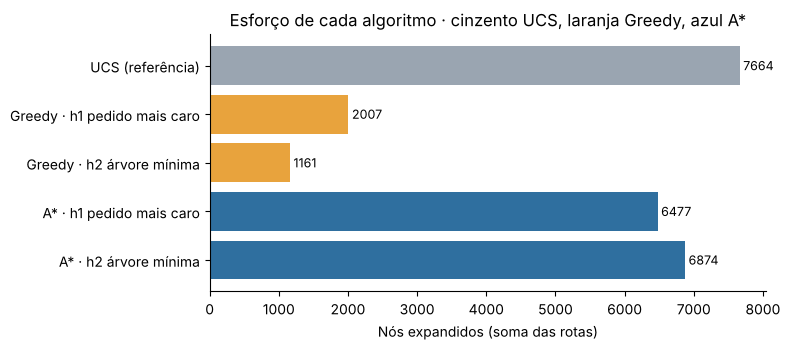

In [21]:
# Gráfico 1: nós expandidos por algoritmo (menos é melhor)
fig, ax = plt.subplots(figsize=(8, 3.6))
cores = ["#9aa5b1" if n.startswith("UCS") else "#e8a33d" if n.startswith("Greedy") else "#2f6f9f"
         for n in tabela_pesquisa["Algoritmo"]]
ax.barh(tabela_pesquisa["Algoritmo"], tabela_pesquisa["Nós expandidos"], color=cores)
for y, v in enumerate(tabela_pesquisa["Nós expandidos"]):
    ax.text(v, y, f" {v}", va="center", fontsize=9)
ax.invert_yaxis()
ax.set_xlabel("Nós expandidos (soma das rotas)")
ax.set_title("Esforço de cada algoritmo · cinzento UCS, laranja Greedy, azul A*")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

In [22]:
# Verificação: todas as soluções são viáveis e o A* dá o mesmo custo que a UCS
assert all(s["viavel"] for s in solucoes.values())
assert all(abs(s["km"] - otimo) < 1e-6 for n, s in solucoes.items() if n.startswith("A*"))
print("✓ Todas as soluções passam no verificador; o A* dá o ótimo da UCS com a h1 e com a h2.")

✓ Todas as soluções passam no verificador; o A* dá o ótimo da UCS com a h1 e com a h2.


**Observações:**
- **O A\* dá sempre os mesmos 879,45 km que a UCS**, o que confirma de novo que as heurísticas são admissíveis.
- **Nós expandidos em relação à UCS (7664):**
  - A\* com a h1: 6477, ou seja, −15 %;
  - A\* com a h2: 6874, ou seja, −10 %.

  A h1 continua a ser a melhor.
- **Porque é que as reduções são menores do que no tiny:** com mais encomendas por veículo há muitos estados com a mesma estimativa, e as heurísticas distinguem-nos menos.
- **O problema cresceu bastante:** com o dobro das encomendas, a UCS expande 7,8 vezes mais nós do que no tiny (978 → 7664).
- **O Greedy:**
  - com a h1, fica muito perto do ótimo (+0,1 %) com 2007 nós;
  - com a h2, só 1161 nós, mas +4,6 %.

#### 4.3.1 Rotas da melhor solução (as rotas dos 2 veículos)

Rotas do A\* com a h1: uma tabela por veículo e por dia, com as horas de chegada e de início do serviço (as janelas limitam o início), a carga a bordo e os km acumulados.

In [23]:
melhor = solucoes["A* · h1 pedido mais caro"]
display(resumo_rotas(melhor))
for r in melhor["rotas"]:
    display(Markdown(f"**Veículo {r['veiculo']} · dia {r['dia']:%d/%m}** — {r['km']} km — "
                     f"tarefas: {', '.join(r['tarefas'])}"))
    display(itinerario(problema, r))

,Dia,Veículo,Tarefas,Peso (kg),Paragens,km,Nós expandidos,Tempo (s)
0,30/10,1,"C1, R5-P1, R5-P5, R5-P6, R11-P1, R11-P3, R11-P...",214.1,7 → 4 → 6 → 1 → 3 → 5 → 7 → 13 → 14 → 12 → 7,286.67,606,0.068
1,30/10,2,"C2, C6, C15, C18",91.0,7 → 4 → 6 → 1 → 2 → 3 → 7 → 10 → 8 → 11 → 7,192.90,736,0.075
2,31/10,1,"E11, E14, E17",79.6,7 → 7 → 11 → 7,39.70,3,0.000
3,31/10,2,"C3, C4, E5, C7, C8, C10, C12, C13, C20, C21, C...",317.8,7 → 7 → 4 → 10 → 9 → 6 → 1 → 2 → 3 → 5 → 7 → 8...,360.18,5132,1.015


**Veículo 1 · dia 30/10** — 286.67 km — tarefas: C1, R5-P1, R5-P5, R5-P6, R11-P1, R11-P3, R11-P5, R11-P6, R14-P3, R14-P4, C16, R17-P5, R17-P6, C19, R23-P1, R23-P6, R25-P1, R25-P4, R25-P5, R25-P6

,Paragem,Local,Chegada,Início,Saída,O que faz,Carga (kg),km
0,7,Centro de Recolha 1,,,06:00,partida,0.0,0.0
1,4,Courela Carvalho,06:00,07:15,07:25,"recolhe 3 itens (enc. 14, 25)",25.4,0.0
2,6,Campos Oliveira,07:56,08:15,08:25,"recolhe 8 itens (enc. 1, 5, 11, 16, 17, 23, 25)",107.4,23.5
3,1,Hortas Valente,08:44,08:45,08:55,"recolhe 6 itens (enc. 5, 11, 19, 23, 25)",146.3,38.4
4,3,Horta Morais,09:47,09:47,09:57,"recolhe 4 itens (enc. 1, 11, 14, 16)",182.4,77.7
5,5,Horta Antunes,11:13,11:13,11:23,"recolhe 6 itens (enc. 5, 11, 16, 17, 19, 25)",214.1,135.0
6,7,Centro de Recolha 1,12:15,12:15,12:45,"armazém: descarrega 27 itens e carrega enc. 1,...",58.0,173.9
7,13,Loja 6,13:04,13:04,13:14,entrega a encomenda 16,26.9,188.2
8,14,Casa 7,13:32,13:32,13:42,entrega a encomenda 19,19.4,201.1
9,12,Restaurante 5,14:26,14:26,14:36,entrega a encomenda 1,0.0,234.3


**Veículo 2 · dia 30/10** — 192.9 km — tarefas: C2, C6, C15, C18

,Paragem,Local,Chegada,Início,Saída,O que faz,Carga (kg),km
0,7,Centro de Recolha 1,,,06:00,partida,0.0,0.0
1,4,Courela Carvalho,06:00,07:15,07:25,"recolhe 3 itens (enc. 2, 6, 18)",22.6,0.0
2,6,Campos Oliveira,07:56,08:15,08:25,"recolhe 5 itens (enc. 2, 6, 15, 18)",61.1,23.5
3,1,Hortas Valente,08:44,08:45,08:55,recolhe 1 itens (enc. 18),65.9,38.4
4,2,Campos Leite,09:26,09:30,09:40,"recolhe 5 itens (enc. 2, 6, 15, 18)",87.2,62.0
5,3,Horta Morais,10:14,10:14,10:24,recolhe 1 itens (enc. 18),91.0,88.0
6,7,Centro de Recolha 1,11:03,11:03,11:33,"armazém: descarrega 15 itens e carrega enc. 2,...",91.0,117.1
7,10,Restaurante 3,11:57,11:57,12:07,"entrega as encomendas 6, 18",37.8,135.2
8,8,Casa 1,12:12,12:12,12:22,entrega a encomenda 15,30.7,139.1
9,11,Loja 4,13:08,13:30,13:40,entrega a encomenda 2,0.0,173.1


**Veículo 1 · dia 31/10** — 39.7 km — tarefas: E11, E14, E17

,Paragem,Local,Chegada,Início,Saída,O que faz,Carga (kg),km
0,7,Centro de Recolha 1,,,06:00,partida,0.0,0.0
1,7,Centro de Recolha 1,06:00,06:00,06:15,"armazém: carrega enc. 11, 14, 17",79.6,0.0
2,11,Loja 4,06:41,08:45,08:55,"entrega as encomendas 11, 14, 17",0.0,19.9
3,7,Centro de Recolha 1,09:21,09:21,09:21,armazém: regresso,0.0,39.7


**Veículo 2 · dia 31/10** — 360.18 km — tarefas: C3, C4, E5, C7, C8, C10, C12, C13, C20, C21, C22, E23, C24, E25

,Paragem,Local,Chegada,Início,Saída,O que faz,Carga (kg),km
0,7,Centro de Recolha 1,,,06:00,partida,0.0,0.0
1,7,Centro de Recolha 1,06:00,06:00,06:15,"armazém: carrega enc. 5, 23, 25",76.5,0.0
2,4,Courela Carvalho,06:15,07:15,07:25,"recolhe 4 itens (enc. 7, 8, 13, 21)",109.4,0.0
3,10,Restaurante 3,07:49,07:49,07:59,entrega a encomenda 23,98.4,18.2
4,9,Restaurante 2,08:15,08:15,08:25,"entrega as encomendas 5, 25",32.9,30.1
5,6,Campos Oliveira,08:55,08:55,09:05,"recolhe 4 itens (enc. 7, 8, 20, 22)",48.1,53.1
6,1,Hortas Valente,09:25,09:25,09:35,"recolhe 4 itens (enc. 3, 10, 12, 13)",62.3,68.0
7,2,Campos Leite,10:06,10:06,10:16,"recolhe 8 itens (enc. 3, 12, 13, 20, 21, 22, 24)",126.4,91.6
8,3,Horta Morais,10:51,10:51,11:01,"recolhe 9 itens (enc. 3, 4, 7, 8, 10, 12, 20, ...",197.5,117.6
9,5,Horta Antunes,12:18,12:18,12:28,"recolhe 5 itens (enc. 3, 4, 7, 24)",241.3,174.9


**Observações:**
- **Dia 30:** os dois veículos saem.
  - O **veículo 1** faz as recolhas das encomendas que dormem no armazém e 3 completas: 214,1 kg, 286,7 km, regresso às 15:46.
  - O **veículo 2** faz 4 completas (192,9 km).
- **Dia 31:**
  - O **veículo 1** carrega às 06:00 três encomendas para o mesmo cliente e entrega-as (39,7 km).
  - O **veículo 2** carrega às 06:00 as outras três encomendas que dormiram no armazém. Entrega-as durante as recolhas e depois faz as 11 completas: 360,2 km, regresso às 18:05.
- **24 h no armazém:** todas as encomendas que passaram a noite são carregadas às 06:00, por isso nenhuma passa do limite.

### 4.4 Pesquisa local — Hill-Climbing sobre a solução do Greedy

O guia pede o Hill-Climbing **a partir da solução do Greedy**:
- **Solução:** as rotas dos veículos. Cada rota é uma sequência de **visitas**, ou seja, uma paragem com as ações que lá se fazem.
- **Vizinhos:** mudar **uma** rota com um de quatro movimentos:
  - **trocar** duas visitas;
  - **mover** uma visita para outra posição;
  - **inverter** um troço (2-opt);
  - **mover bloco** (or-opt): 2 ou 3 visitas seguidas mudam de sítio juntas, na mesma ordem ou invertidas. Este movimento veio do trabalho do Alexandre: deixa mudar duas entregas ao mesmo tempo, coisa que um só movimento simples não consegue sem violar uma janela.

  O regresso final ao armazém fica fixo.
- **Viabilidade:** um vizinho só conta se a solução **inteira** passar no verificador. Mudar uma recolha no dia 30 pode estragar as 24 h no dia 31, por isso verifica-se tudo.
- **Duas estratégias** (a primeira melhoria foi proposta pelo André):
  - **melhor vizinho** (subida mais íngreme): avalia todos e escolhe o melhor;
  - **primeira melhoria**: percorre os vizinhos por ordem aleatória e aceita o primeiro que melhora.

  Pára quando nenhum vizinho tem menos km (ótimo local).

Partimos das duas soluções do Greedy (h1 e h2), com as duas estratégias, e comparamos com o ótimo da secção 4.3.

**Opções consideradas:**

| Decisão | Opções | Escolha | Porquê |
|---|---|---|---|
| Algoritmo | Hill-Climbing · Simulated Annealing · Tabu | **Hill-Climbing** | Pedido pelo guia; simples e determinístico |
| Estratégia | melhor vizinho · primeira melhoria | **as duas, comparadas** | A primeira faz iterações mais baratas; a melhor dá passos maiores |
| Ponto de partida | aleatório · Greedy | **Greedy h1 e Greedy h2** | Pedido pelo guia ("on top of the Greedy solution") |
| Vizinhança | trocar · mover · inverter (2-opt) · mover bloco (or-opt) · mudar de veículo | **os quatro primeiros**, dentro de uma rota | Mudar de veículo é decisão do CSP |
| Vizinhos inviáveis | penalizar · descartar | **descartar** (verificador completo) | Garante que a solução final cumpre todas as regras |

In [24]:
# Hill-Climbing: vizinhos (trocar, mover, inverter) e subida mais íngreme

Rota = Tuple[int, list, datetime]          # (veículo, ações, hora de partida)


def _achatar(grupos) -> list:
    return [acao for grupo in grupos for acao in grupo]


def vizinhos(problem: Problem, rotas: List[Rota]) -> Iterator[Tuple[str, List[Rota]]]:
    """
    Gera (descrição do movimento, nova solução) para todos os movimentos possíveis:
      troca, mover, inverter (2-opt) e mover bloco (or-opt: 2 ou 3 visitas seguidas
      mudam de sítio juntas, na mesma ordem ou invertidas — sugestão do Alexandre).
    """
    for k, (veiculo, acoes, partida) in enumerate(rotas):
        vis = visitas(problem, acoes)
        n = len(vis) - 1                      # a última visita (regresso) fica fixa
        for i in range(n):
            for j in range(n):
                if i == j:
                    continue
                if i < j:                     # troca e inversão: cada par uma só vez
                    nova = vis[:]
                    nova[i], nova[j] = nova[j], nova[i]
                    yield f"rota {k + 1}: troca visitas {i + 1}↔{j + 1}", _substituir(rotas, k, _achatar(nova))
                    if j - i >= 2:
                        nova = vis[:i] + vis[i:j + 1][::-1] + vis[j + 1:]
                        yield f"rota {k + 1}: inverte visitas {i + 1}–{j + 1}", _substituir(rotas, k, _achatar(nova))
                if abs(i - j) >= 2 or i > j:  # mover (j = nova posição)
                    nova = vis[:]
                    visita = nova.pop(i)
                    nova.insert(j, visita)
                    yield f"rota {k + 1}: move visita {i + 1}→{j + 1}", _substituir(rotas, k, _achatar(nova))
        for tamanho in (2, 3):                # mover bloco
            for i in range(n - tamanho + 1):
                bloco, resto = vis[i:i + tamanho], vis[:i] + vis[i + tamanho:n]
                for j in range(len(resto) + 1):
                    if j == i:
                        continue
                    for invertido in (False, True):
                        b = bloco[::-1] if invertido else bloco
                        nova = resto[:j] + b + resto[j:] + vis[n:]
                        sufixo = " (invertido)" if invertido else ""
                        yield (f"rota {k + 1}: move bloco {i + 1}–{i + tamanho}→{j + 1}{sufixo}",
                               _substituir(rotas, k, _achatar(nova)))


def _substituir(rotas: List[Rota], k: int, acoes: list) -> List[Rota]:
    nova = list(rotas)
    veiculo, _, partida = rotas[k]
    nova[k] = (veiculo, acoes, partida)
    return nova


def avaliar(problem: Problem, rotas: List[Rota], objetivo: set) -> Optional[float]:
    """km da solução, ou None se não for viável."""
    v = verificar_solucao(problem, rotas, itens_objetivo=objetivo)
    return v["distancia_km"] if v["viavel"] else None


def hill_climbing(problem: Problem, rotas: List[Rota], objetivo: set,
                  estrategia: str = "melhor", max_iteracoes: int = 200, semente: int = 0) -> Dict[str, object]:
    """
    Hill-Climbing. Devolve as rotas finais, a curva custo × iteração (iteração 0 = solução
    inicial), os movimentos aceites, os vizinhos avaliados e o tempo de execução.
      estrategia = "melhor":   avalia todos os vizinhos e passa para o melhor (subida mais íngreme);
      estrategia = "primeira": percorre os vizinhos por ordem aleatória e aceita o primeiro que
                               melhora (primeira melhoria — sugestão do André).
    """
    import random
    rnd = random.Random(semente)
    inicio = time.perf_counter()
    atual = list(rotas)
    custo = avaliar(problem, atual, objetivo)
    if custo is None:
        raise ValueError("A solução inicial não é viável.")
    curva, movimentos, avaliados = [custo], [], 0

    for _ in range(max_iteracoes):
        candidatos = list(vizinhos(problem, atual))
        if estrategia == "primeira":
            rnd.shuffle(candidatos)
        melhor, melhor_custo, melhor_mov = None, custo, None
        for descricao, vizinho in candidatos:
            avaliados += 1
            c = avaliar(problem, vizinho, objetivo)
            if c is not None and c < melhor_custo - 1e-9:
                melhor, melhor_custo, melhor_mov = vizinho, c, descricao
                if estrategia == "primeira":
                    break                             # aceita logo o primeiro que melhora
        if melhor is None:
            break                                     # ótimo local: nenhum vizinho melhora
        atual, custo = melhor, melhor_custo
        curva.append(custo)
        movimentos.append(f"{melhor_mov}  ({curva[-2]:.2f} → {custo:.2f} km)")

    return {"rotas": atual, "km": round(custo, 2), "curva": curva, "movimentos": movimentos,
            "vizinhos_avaliados": avaliados, "tempo_s": round(time.perf_counter() - inicio, 2)}

In [25]:
objetivo = {i for i, r in problema.pedidos.items() if r.order_id not in melhor["adiadas"]}
resultados_hc = {}
for nome in ("Greedy · h1 pedido mais caro", "Greedy · h2 árvore mínima"):
    inicial = [(r["veiculo"], r["acoes"], r["partida"]) for r in solucoes[nome]["rotas"]]
    for estrategia in ("melhor", "primeira"):
        resultados_hc[(nome, estrategia)] = hill_climbing(problema, inicial, objetivo, estrategia)

pd.DataFrame([{
    "Ponto de partida": nome, "Estratégia": "melhor vizinho" if est == "melhor" else "primeira melhoria",
    "km inicial": hc["curva"][0], "km final": hc["km"], "Ótimo (A*)": otimo,
    "Iterações": len(hc["curva"]) - 1, "Vizinhos avaliados": hc["vizinhos_avaliados"], "Tempo (s)": hc["tempo_s"],
    "Chegou ao ótimo?": "sim" if abs(hc["km"] - otimo) < 0.05 else "não (ótimo local)",
} for (nome, est), hc in resultados_hc.items()])

,Ponto de partida,Estratégia,km inicial,km final,Ótimo (A*),Iterações,Vizinhos avaliados,Tempo (s),Chegou ao ótimo?
0,Greedy · h1 pedido mais caro,melhor vizinho,880.53,879.45,879.45,1,3768,1.56,sim
1,Greedy · h1 pedido mais caro,primeira melhoria,880.53,879.45,879.45,1,3452,1.45,sim
2,Greedy · h2 árvore mínima,melhor vizinho,919.82,879.45,879.45,3,7536,3.17,sim
3,Greedy · h2 árvore mínima,primeira melhoria,919.82,879.45,879.45,4,3175,1.42,sim


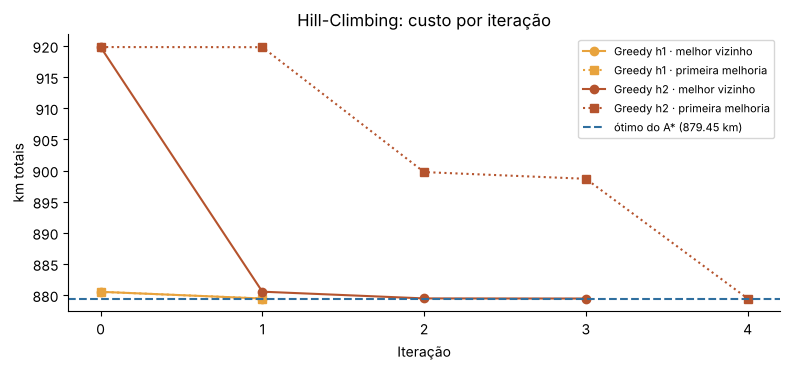

Movimentos aceites a partir do Greedy · h1 pedido mais caro (melhor):
    rota 4: move bloco 5–6→3 (invertido)  (880.53 → 879.45 km)
Movimentos aceites a partir do Greedy · h1 pedido mais caro (primeira):
    rota 4: move bloco 5–6→3 (invertido)  (880.53 → 879.45 km)
Movimentos aceites a partir do Greedy · h2 árvore mínima (melhor):
    rota 2: troca visitas 1↔2  (919.82 → 880.55 km)
    rota 4: move bloco 5–6→3 (invertido)  (880.55 → 879.47 km)
    rota 2: troca visitas 7↔8  (879.47 → 879.45 km)
Movimentos aceites a partir do Greedy · h2 árvore mínima (primeira):
    rota 2: troca visitas 7↔8  (919.82 → 919.80 km)
    rota 2: move visita 1→3  (919.80 → 899.75 km)
    rota 4: move bloco 5–6→3 (invertido)  (899.75 → 898.67 km)
    rota 2: move visita 3→2  (898.67 → 879.45 km)


In [26]:
# Gráfico 2: custo por iteração do Hill-Climbing
fig, ax = plt.subplots(figsize=(8, 3.8))
cores = {"Greedy · h1 pedido mais caro": "#e8a33d", "Greedy · h2 árvore mínima": "#b5532d"}
for (nome, est), hc in resultados_hc.items():
    ax.plot(range(len(hc["curva"])), hc["curva"], marker="o" if est == "melhor" else "s",
            linestyle="-" if est == "melhor" else ":", color=cores[nome],
            label=f"{nome.split(' ·')[0]} {nome.split()[2]} · {'melhor vizinho' if est == 'melhor' else 'primeira melhoria'}")
ax.axhline(otimo, color="#2f6f9f", linestyle="--", label=f"ótimo do A* ({otimo} km)")
ax.set_xlabel("Iteração")
ax.set_ylabel("km totais")
ax.set_title("Hill-Climbing: custo por iteração")
ax.xaxis.get_major_locator().set_params(integer=True)
ax.legend(fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

for (nome, est), hc in resultados_hc.items():
    print(f"Movimentos aceites a partir do {nome} ({est}):")
    for m in hc["movimentos"]:
        print("   ", m)

In [27]:
# Verificação: a curva nunca sobe e a solução final é viável
for chave, hc in resultados_hc.items():
    assert all(b2 <= a2 + 1e-9 for a2, b2 in zip(hc["curva"], hc["curva"][1:])), chave
    assert verificar_solucao(problema, hc["rotas"], objetivo)["viavel"], chave
print("✓ O Hill-Climbing nunca aumenta os km e termina sempre numa solução viável.")

✓ O Hill-Climbing nunca aumenta os km e termina sempre numa solução viável.


**Observações:**
- **As quatro combinações chegam ao valor do A\* (879,45 km).**
- **Greedy h1:** só falta 1,08 km, e o último passo é um **mover bloco**: duas visitas seguidas mudam de sítio juntas e invertidas. Nos testes do Alexandre no protótipo, só com os três movimentos de base o Hill-Climbing ficava preso nos 880,53 km.
- **Greedy h2:**
  - o **melhor vizinho** precisa de 3 iterações e 7536 avaliações;
  - a **primeira melhoria** precisa de 4 iterações, mas só 3175 avaliações, menos de metade.
- **É rápido:** 1 a 4 s por execução.

## 5. Análise de resultados

### 5.1 Tabela final

In [28]:
g1, g2 = "Greedy · h1 pedido mais caro", "Greedy · h2 árvore mínima"
a1, a2 = "A* · h1 pedido mais caro", "A* · h2 árvore mínima"
final = [
    ("UCS (referência)", otimo, solucoes["UCS (referência)"]["tempo_s"], "ótimo garantido, mais nós"),
    (a1, solucoes[a1]["km"], solucoes[a1]["tempo_s"], "ótimo garantido, menos nós"),
    (a2, solucoes[a2]["km"], solucoes[a2]["tempo_s"], "ótimo garantido"),
    (g1, solucoes[g1]["km"], solucoes[g1]["tempo_s"], "rápido, sem garantia"),
    (g2, solucoes[g2]["km"], solucoes[g2]["tempo_s"], "rápido, sem garantia"),
]
for (nome, est), hc in resultados_hc.items():
    final.append((f"{nome} + HC ({est})", hc["km"], solucoes[nome]["tempo_s"] + hc["tempo_s"], "melhora o Greedy"))
display(pd.DataFrame([{"Método": m, "km": km, "Acima do ótimo": f"{(km - otimo) / otimo * 100:.1f} %",
                       "Tempo das rotas (s)": round(t, 3), "Nota": nota} for m, km, t, nota in final]))
adiadas = melhor["adiadas"]
print(f"Divisão pelos veículos (CSP): {tempo_csp:.1f} s · "
      f"encomendas servidas: {len(encomendas) - len(adiadas)} de {len(encomendas)}"
      + (f" · adiadas: {', '.join(map(str, adiadas))}" if adiadas else ""))
print(f"Melhor solução: {otimo} km, verificada: {melhor['viavel']}")

,Método,km,Acima do ótimo,Tempo das rotas (s),Nota
0,UCS (referência),879.45,0.0 %,1.006,"ótimo garantido, mais nós"
1,A* · h1 pedido mais caro,879.45,0.0 %,1.161,"ótimo garantido, menos nós"
2,A* · h2 árvore mínima,879.45,0.0 %,1.153,ótimo garantido
3,Greedy · h1 pedido mais caro,880.53,0.1 %,0.388,"rápido, sem garantia"
4,Greedy · h2 árvore mínima,919.82,4.6 %,0.249,"rápido, sem garantia"
5,Greedy · h1 pedido mais caro + HC (melhor),879.45,0.0 %,1.948,melhora o Greedy
6,Greedy · h1 pedido mais caro + HC (primeira),879.45,0.0 %,1.838,melhora o Greedy
7,Greedy · h2 árvore mínima + HC (melhor),879.45,0.0 %,3.419,melhora o Greedy
8,Greedy · h2 árvore mínima + HC (primeira),879.45,0.0 %,1.669,melhora o Greedy


Divisão pelos veículos (CSP): 137.5 s · encomendas servidas: 24 de 25 · adiadas: 9
Melhor solução: 879.45 km, verificada: True


### 5.2 Análise crítica

**Melhor solução:** **879,45 km**, com **24 das 25 encomendas** entregues pelos 2 veículos nos 2 dias, e passa no verificador. A encomenda 9 fica adiada porque o CSP provou que o dia 30 é impossível com 2 veículos neste modelo.
- **As rotas são ótimas para a divisão escolhida**, porque o A\* dá o mesmo valor que a UCS.
- **A divisão é a melhor que encontrámos, mas não está provada ótima.**
- **Confirmação externa:** o protótipo do Alexandre, feito de outra forma, chegou exatamente ao mesmo valor (879,45 km), o que dá confiança no resultado.

**Tempos de execução:**
- **CSP (≈ 2,5 min):** domina o tempo total.
- **Rotas, depois de dividir:** cerca de 1 s.
- **Hill-Climbing:** 1 a 4 s.

**Comparação com o tiny:**

| | tiny | small |
|---|---|---|
| Encomendas | 12 | 25 |
| Nós da UCS | 978 | 7664 (×7,8) |
| Redução do A\* com a h1 | −52 % | −15 % |
| Variáveis do CSP no dia 30 | 11 | 25 |
| Possível com 2 veículos? | sim | não (1 adiada) |
| km | 561,3 | 879,45 |

**Melhorias futuras:**
1. **Servir a encomenda 9:**
   - cooperação no armazém, em que um veículo recolhe no produtor 5 e o outro entrega no mesmo dia;
   - ou um 3.º veículo.
2. **Divisão pelos veículos:** *branch and bound*, ou pesquisa local sobre a atribuição, para provar ou melhorar a divisão.
3. **Pesquisa local:** *Simulated Annealing* ou reinícios aleatórios.
4. **Função de custo:** tempo de trabalho e equilíbrio de carga, para além dos km.

## 6. Conclusão

**O mesmo código do tiny resolve o small**, que é mais complexo. Só muda a linha `PASTA`.

**O que o small mostra que o tiny não mostrava:**
- **O CSP também prova impossibilidades.** Com 2 veículos e encomendas completas num só veículo, o dia 30 não tem solução. O MRV prova-o com 10 backtracks em vez de 268.
- **O modo relaxado transforma essa prova numa resposta útil:** adia uma única encomenda.
- **A capacidade por viagem**, que veio do trabalho do Fábio, deixa um veículo fazer várias cargas no mesmo dia. Baixou o total para 879,45 km.
- **A pesquisa local precisa de uma vizinhança rica.** O mover bloco, que veio do trabalho do Alexandre, é o que tira o Greedy h1 do ótimo local.
- **A h1 continua a ser a heurística mais informada**, e o Greedy + Hill-Climbing chega ao mesmo valor do A\*.

**Sobre o processo e as ferramentas:**
- **Camadas separadas:** modelo, verificador, pesquisa, CSP e pesquisa local permitiram passar do tiny para o small sem mudar o código.
- **python-constraint:** facilitou a formulação, mas não dá o número de backtracks, por isso escrevemos um backtracking simples para o medir.